# Notebook 07 — Clinical Longformer Frozen-Encoder Baseline

This notebook trains and evaluates a **non-fine-tuned Clinical Longformer baseline** for one binary task at a time:

- **depression detection**, or
- **anxiety detection**.

The pretrained `yikuan8/Clinical-Longformer` encoder is frozen. Only its task-specific classification head is trained. This provides a controlled baseline for comparison with the fully fine-tuned Clinical Longformer while retaining the same dataset, long-context input, global-attention policy, model-selection procedure and evaluation workflow.

The experiment uses only the masked task dataset, uses `text_selected`, retains the 2,048-token context window, preserves the existing patient-level train/validation/test assignments, calculates class weights from the training split only, selects the best checkpoint and classification threshold using validation data only, and evaluates the test split only after all decisions are fixed.

## Input strategy

Each selected discharge note remains one classification example. The tokenizer measures exact input length and reports truncation at 512, 1,024, 2,048 and 4,096 tokens. Inputs are truncated to 2,048 tokens only when necessary. The first `<s>` token receives global attention, while other non-padding tokens use Longformer's local attention.

> Run the notebook first with `SMOKE_TEST = True`. After the complete pipeline succeeds, change it to `False` for the full experiment.

The notebook preserves the fine-tuned version's progress reporting, class-weighted loss, checkpointing, validation-only threshold selection, learning curves, classification report, confusion matrix, ROC/PR curves, prediction exports and Flask-ready deployment bundle. It also performs a full parameter-fingerprint audit proving that every pretrained encoder tensor stayed unchanged while the classification head learned.

## 1. Environment and dependencies

Install the required libraries once in the active CUDA environment if they are not already available:

```bash
pip install torch transformers datasets accelerate scikit-learn pyarrow pandas matplotlib seaborn tqdm
```

The existing ClinicalBERT CUDA kernel can be used if these packages are installed in that kernel. After installing or upgrading packages—or after a CUDA out-of-memory error—restart the Jupyter kernel before running the notebook from the beginning.


In [39]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES AND VERIFY DEPENDENCIES
# ============================================================

from pathlib import Path
from contextlib import nullcontext
import gc
import hashlib
import html
import json
import math
import os
import random
import sys
import time

# Reduce CUDA-memory fragmentation. This must be set before CUDA is initialised.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F

from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader
import datasets as hf_datasets
from datasets import Dataset, DatasetDict
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import transformers
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)
from tqdm.auto import tqdm
from IPython.display import display, HTML

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Python environment:", sys.executable)
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Datasets version:", hf_datasets.__version__)


Python environment: C:\ProgramData\anaconda3\envs\clinicalbert-gpu\python.exe
PyTorch version: 2.6.0+cu124
Transformers version: 5.17.0
Datasets version: 5.0.1


In [40]:
# ============================================================
# CELL 2 - SET RANDOM SEEDS AND SELECT DEVICE
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Selected device:", DEVICE)


Random seed: 42
Selected device: cuda


## 2. Experiment configuration

The main settings are deliberately kept in one cell. To run the other task, change only:

```python
TASK_NAME = "anxiety"
```

The notebook selects the matching masked dataset and writes to a separate task-specific output directory. The default 2,048-token configuration is designed for a single 16 GB NVIDIA T4 using batch size 1, gradient accumulation, mixed precision and gradient checkpointing.


In [41]:
# ============================================================
# CELL 3 - LOCATE THE PROJECT ROOT
# ============================================================

def find_project_root(starting_path):
    starting_path = Path(starting_path).expanduser().resolve()
    for location in [starting_path, *starting_path.parents]:
        if (location / ".git").exists() or (location / "dataset").exists():
            return location

    raise FileNotFoundError(
        "Could not locate the project root. " "Open Jupyter from inside the project repository."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_DIR = PROJECT_ROOT / "dataset"
print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)


Project root: C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection
Dataset directory: C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\dataset


In [42]:
# ============================================================
# CELL 4 - CONFIGURE THE CLINICAL LONGFORMER BASELINE
# ============================================================

# Choose one task: "depression" or "anxiety".
TASK_NAME = "depression"

MODEL_DATASET_FOLDER = "model_datasets"
MODEL_NAME = "yikuan8/Clinical-Longformer"
TEXT_COLUMN = "text_selected"
MAX_LENGTH = 2048
CONTEXT_LENGTHS_TO_AUDIT = [512, 1024, 2048, 4096]
LONGFORMER_ATTENTION_WINDOW = 512
TRAINING_STRATEGY = "frozen_encoder_classification_head_only"

# Start with True. Change to False only after the smoke run passes.
SMOKE_TEST = False
SMOKE_SPLIT_SIZES = {"train": 50, "validation": 10, "test": 10}
EVALUATE_TEST_SET = True
NUMBER_OF_EPOCHS = 1 if SMOKE_TEST else 15

# The larger 1e-4 learning rate is shared by the frozen-encoder baselines.
# It is applied only to the small randomly initialized classification head.
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
WARMUP_PROPORTION = 0.10
MAX_GRADIENT_NORM = 1.0
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MINIMUM_IMPROVEMENT = 1e-4
STOP_TRAINING_WHEN_PATIENCE_REACHED = False
SAVE_EARLY_STOP_SIGNAL_MODEL = True

# Encoder activations do not require backward gradients in this baseline, so
# gradient checkpointing would add recomputation overhead without a benefit.
USE_GRADIENT_CHECKPOINTING = False
EXAMPLE_RECORDS_PER_SPLIT = 5
PREDICTION_DISPLAY_COUNT = 100
REPORT_FIGURE_DPI = 300

if DEVICE.type == "cuda":
    TRAIN_BATCH_SIZE = 1
    EVALUATION_BATCH_SIZE = 2
    GRADIENT_ACCUMULATION_STEPS = 16
    USE_MIXED_PRECISION = True
elif DEVICE.type == "mps":
    TRAIN_BATCH_SIZE = 1
    EVALUATION_BATCH_SIZE = 1
    GRADIENT_ACCUMULATION_STEPS = 16
    USE_MIXED_PRECISION = False
else:
    TRAIN_BATCH_SIZE = 1
    EVALUATION_BATCH_SIZE = 1
    GRADIENT_ACCUMULATION_STEPS = 16
    USE_MIXED_PRECISION = False

if TASK_NAME not in {"depression", "anxiety"}:
    raise ValueError("TASK_NAME must be either 'depression' or 'anxiety'.")
if MAX_LENGTH not in CONTEXT_LENGTHS_TO_AUDIT:
    raise ValueError("MAX_LENGTH must be included in CONTEXT_LENGTHS_TO_AUDIT.")
if MAX_LENGTH > 4096:
    raise ValueError("Clinical Longformer supports at most 4,096 input tokens.")

MODEL_DATASET_DIR = DATASET_DIR / MODEL_DATASET_FOLDER
DATASET_PATHS = {
    "depression": MODEL_DATASET_DIR / "depression_dataset_masked.parquet",
    "anxiety": MODEL_DATASET_DIR / "anxiety_dataset_masked.parquet",
}
DATASET_PATH = DATASET_PATHS[TASK_NAME]
RUN_MODE = "smoke" if SMOKE_TEST else "full"
TEXT_STRATEGY = "selected" if TEXT_COLUMN == "text_selected" else "full"

# Keep generated paths short enough for Windows-based AWS environments.
RUN_NAME = f"{TASK_NAME}_{TEXT_STRATEGY}_{MAX_LENGTH}_{RUN_MODE}"
OUTPUT_DIR = PROJECT_ROOT / "model_outputs" / "clinical_longformer_baseline" / RUN_NAME
BEST_MODEL_DIR = OUTPUT_DIR / "best_model"
EARLY_STOP_SIGNAL_MODEL_DIR = OUTPUT_DIR / "early_stop_signal_model"
FINAL_EPOCH_MODEL_DIR = OUTPUT_DIR / "final_epoch_model"
DEPLOYMENT_BUNDLE_DIR = OUTPUT_DIR / "deployment_bundle"
DEPLOYMENT_MODEL_DIR = DEPLOYMENT_BUNDLE_DIR / "model"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_CACHE_DIR = Path(r"C:\hf_cache") if os.name == "nt" else (
    PROJECT_ROOT / "model_cache" / "huggingface_models"
)

for directory in [
    OUTPUT_DIR,
    BEST_MODEL_DIR,
    EARLY_STOP_SIGNAL_MODEL_DIR,
    FINAL_EPOCH_MODEL_DIR,
    DEPLOYMENT_MODEL_DIR,
    PREDICTION_DIR,
    FIGURE_DIR,
    MODEL_CACHE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

configuration_table = pd.DataFrame(
    {
        "setting": [
            "Task", "Dataset", "Text field", "Model", "Training strategy",
            "Maximum tokens", "Attention window", "Global attention", "Run mode",
            "Maximum epochs", "Stop when patience is reached",
            "Early-stopping patience", "Minimum PR-AUC improvement", "Device",
            "Training batch size", "Gradient accumulation", "Effective batch size",
            "Evaluation batch size", "Learning rate", "Mixed precision",
            "Gradient checkpointing", "Output directory",
        ],
        "value": [
            TASK_NAME, str(DATASET_PATH), TEXT_COLUMN, MODEL_NAME, TRAINING_STRATEGY,
            MAX_LENGTH, LONGFORMER_ATTENTION_WINDOW, "First token (<s>)", RUN_MODE,
            NUMBER_OF_EPOCHS, STOP_TRAINING_WHEN_PATIENCE_REACHED,
            EARLY_STOPPING_PATIENCE, EARLY_STOPPING_MINIMUM_IMPROVEMENT,
            str(DEVICE), TRAIN_BATCH_SIZE, GRADIENT_ACCUMULATION_STEPS,
            TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
            EVALUATION_BATCH_SIZE, LEARNING_RATE, USE_MIXED_PRECISION,
            USE_GRADIENT_CHECKPOINTING, str(OUTPUT_DIR),
        ],
    }
)
display(configuration_table)

,setting,value
0,Task,depression
1,Dataset,C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\dataset...
2,Text field,text_selected
3,Model,yikuan8/Clinical-Longformer
4,Training strategy,frozen_encoder_classification_head_only
5,Maximum tokens,2048
6,Attention window,512
7,Global attention,First token (<s>)
8,Run mode,full
9,Maximum epochs,15


## 3. Load and validate the masked task dataset

Only the columns required for modelling and traceability are loaded. No text cleaning, masking, section extraction, or split creation is repeated here.


In [43]:
# ============================================================
# CELL 5 - LOAD THE SELECTED MASKED DATASET
# ============================================================

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}\n"
        "Run Notebook 03 first, or check "
        "MODEL_DATASET_FOLDER in Cell 4."
    )

REQUIRED_COLUMNS = ["subject_id", "hadm_id", "split", "label", TEXT_COLUMN]
model_data = pd.read_parquet(DATASET_PATH, columns=REQUIRED_COLUMNS)
model_data = model_data.rename(columns={TEXT_COLUMN: "model_text"})
model_data["split"] = (
    model_data["split"].astype(str).str.strip().str.lower().replace({"val": "validation"})
)
model_data["label"] = model_data["label"].astype(int)
print("Loaded dataset:", DATASET_PATH.name)
print("Rows:", f"{len(model_data):,}")
print("Columns:", model_data.columns.tolist())
display(model_data.head())


Loaded dataset: depression_dataset_masked.parquet
Rows: 180,246
Columns: ['subject_id', 'hadm_id', 'split', 'label', 'model_text']


,subject_id,hadm_id,split,label,model_text
0,10000084,23052089,train,0,past medical history: [DEID] disease\n[DEID] Body Dementia \ndyslipidemia \nprostate cancer (s/p prostatectomy)\n\nc...
1,10000764,27897940,train,0,past medical history: MI after AAA repair when he was [DEID] y/o\nHTN\nHypercholesterolemia\n\nchief complaint: Epis...
2,10000980,29654838,test,0,"past medical history: 1. CAD RISK FACTORS: +Diabetes, +Dyslipidemia, +Hypertension\n2. CARDIAC HISTORY: \nMI in [DEI..."
3,10000980,26913865,test,0,past medical history: - hypertension\n- diabetes\n- hx CVA (cerebellar-medullary stroke in [DEID]\n- CAD (has never ...
4,10000980,24947999,test,0,past medical history: - hypertension \n- diabetes \n- hx CVA (cerebellar-medullary stroke in [DEID] \n- CAD (hx of M...


In [44]:
# ============================================================
# CELL 6 - RUN DATA INTEGRITY CHECKS
# ============================================================

EXPECTED_SPLITS = {"train", "validation", "test"}
observed_splits = set(model_data["split"].unique())
if observed_splits != EXPECTED_SPLITS:
    raise ValueError(
        "Unexpected split values. " f"Expected {EXPECTED_SPLITS}, " f"but found {observed_splits}."
    )

observed_labels = set(model_data["label"].unique())
if not observed_labels.issubset({0, 1}):
    raise ValueError("The label column must contain only 0 and 1.")

if model_data["hadm_id"].isna().any():
    raise ValueError("Missing hadm_id values were found.")

if model_data["subject_id"].isna().any():
    raise ValueError("Missing subject_id values were found.")

if model_data["hadm_id"].duplicated().any():
    duplicate_count = int(model_data["hadm_id"].duplicated().sum())
    raise ValueError(f"Found {duplicate_count:,} duplicate admissions.")

invalid_text_mask = model_data["model_text"].isna() | model_data["model_text"].astype(
    str
).str.strip().eq("")
if invalid_text_mask.any():
    raise ValueError(f"Found {int(invalid_text_mask.sum()):,} " "missing or empty text values.")

subject_split_counts = model_data.groupby("subject_id")["split"].nunique()
cross_split_subject_count = int((subject_split_counts > 1).sum())
if cross_split_subject_count > 0:
    raise ValueError(
        f"Found {cross_split_subject_count:,} patients "
        "appearing in more than one split. "
        "This would cause patient-level data leakage."
    )

class_count_by_split = model_data.groupby("split")["label"].nunique()
if (class_count_by_split < 2).any():
    raise ValueError("Every split must contain both classes.")

print("All dataset integrity checks passed.")
print("Patients appearing in multiple splits:", cross_split_subject_count)


All dataset integrity checks passed.
Patients appearing in multiple splits: 0


In [45]:
# ============================================================
# CELL 7 - CREATE THE FIXED DATASET SPLITS
# ============================================================

SPLIT_ORDER = ["train", "validation", "test"]
split_frames = {
    split_name: (model_data.loc[model_data["split"].eq(split_name)].copy().reset_index(drop=True))
    for split_name in SPLIT_ORDER
}
split_summary_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    negative_count = int(split_frame["label"].eq(0).sum())
    positive_count = int(split_frame["label"].eq(1).sum())
    split_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "patients": split_frame["subject_id"].nunique(),
            "negative": negative_count,
            "positive": positive_count,
            "positive_percentage": round(positive_count / len(split_frame) * 100, 2),
        }
    )

original_split_summary = pd.DataFrame(split_summary_rows)
display(original_split_summary)


,split,admissions,patients,negative,positive,positive_percentage
0,train,126226,53959,104051,22175,17.57
1,validation,27238,11566,22497,4741,17.41
2,test,26782,11561,22173,4609,17.21


### Smoke-test sampling

The smoke test takes a reproducible, stratified subset **within each existing split**. It does not move patients or admissions between splits and does not create new split assignments.


In [46]:
# ============================================================
# CELL 8 - CREATE REPRODUCIBLE SMOKE-TEST SUBSETS
# ============================================================

def create_stratified_subset(frame, sample_size, random_state):
    if sample_size >= len(frame):
        return frame.copy().reset_index(drop=True)

    selected_frame, _ = train_test_split(
        frame, train_size=sample_size, stratify=frame["label"], random_state=random_state
    )
    return selected_frame.sample(frac=1.0, random_state=random_state).reset_index(drop=True)

if SMOKE_TEST:
    smoke_seed_offsets = {"train": 0, "validation": 1, "test": 2}
    split_frames = {
        split_name: create_stratified_subset(
            frame=split_frames[split_name],
            sample_size=SMOKE_SPLIT_SIZES[split_name],
            random_state=(SEED + smoke_seed_offsets[split_name]),
        )
        for split_name in SPLIT_ORDER
    }

working_split_summary_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    negative_count = int(split_frame["label"].eq(0).sum())
    positive_count = int(split_frame["label"].eq(1).sum())
    working_split_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "negative": negative_count,
            "positive": positive_count,
            "positive_percentage": round(positive_count / len(split_frame) * 100, 2),
        }
    )

working_split_summary = pd.DataFrame(working_split_summary_rows)
print("Run mode:", RUN_MODE)
display(working_split_summary)


Run mode: full


,split,admissions,negative,positive,positive_percentage
0,train,126226,104051,22175,17.57
1,validation,27238,22497,4741,17.41
2,test,26782,22173,4609,17.21


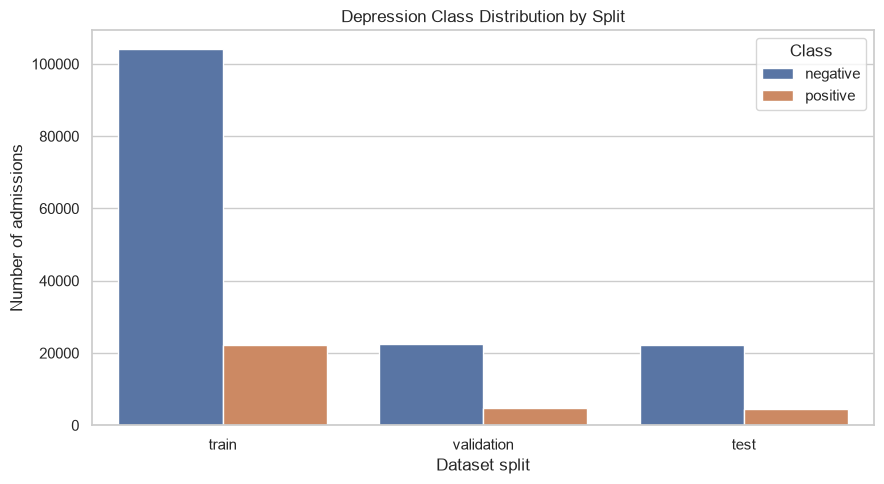

In [47]:
# ============================================================
# CELL 9 - VISUALISE THE WORKING CLASS DISTRIBUTIONS
# ============================================================

class_plot_data = working_split_summary[["split", "negative", "positive"]].melt(
    id_vars="split", var_name="class_name", value_name="admissions"
)
plt.figure(figsize=(9, 5))
sns.barplot(data=class_plot_data, x="split", y="admissions", hue="class_name", order=SPLIT_ORDER)
plt.title(f"{TASK_NAME.title()} Class Distribution by Split")
plt.xlabel("Dataset split")
plt.ylabel("Number of admissions")
plt.legend(title="Class")
plt.tight_layout()
class_distribution_plot_path = FIGURE_DIR / "class_distribution.png"
plt.savefig(class_distribution_plot_path, dpi=200, bbox_inches="tight")
plt.show()


## 4. Load the Clinical Longformer tokenizer and audit input length

Notebook 02 may contain approximate token counts. This section uses the exact Clinical Longformer tokenizer and measures every working example before truncation.

Because the previous models were limited to 512 tokens, the notebook reports the percentage exceeding 512, 1,024, 2,048 and 4,096 tokens. This distinguishes the earlier 512-token bottleneck from truncation remaining under the selected Longformer context window.


In [48]:
# ============================================================
# CELL 10 - LOAD THE CLINICAL LONGFORMER TOKENIZER
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    cache_dir=str(MODEL_CACHE_DIR),
    use_fast=True,
)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer:", tokenizer.__class__.__name__)
print("Fast tokenizer:", tokenizer.is_fast)
print("Vocabulary size:", f"{tokenizer.vocab_size:,}")
print("Tokenizer maximum length:", tokenizer.model_max_length)
print("Experiment maximum length:", MAX_LENGTH)


Tokenizer: RobertaTokenizer
Fast tokenizer: True
Vocabulary size: 50,265
Tokenizer maximum length: 4096
Experiment maximum length: 2048


In [49]:
# ============================================================
# CELL 11 - CALCULATE EXACT TOKEN COUNTS AND CONTEXT COVERAGE
# ============================================================

TOKEN_LENGTH_BATCH_SIZE = 64

def calculate_token_lengths(texts, tokenizer_object, batch_size):
    token_lengths = []
    original_maximum = tokenizer_object.model_max_length
    tokenizer_object.model_max_length = 10**9
    try:
        for batch_start in range(0, len(texts), batch_size):
            encoded_batch = tokenizer_object(
                texts[batch_start:batch_start + batch_size],
                add_special_tokens=True,
                truncation=False,
                padding=False,
                return_attention_mask=False,
                return_token_type_ids=False,
            )
            token_lengths.extend(len(ids) for ids in encoded_batch["input_ids"])
    finally:
        tokenizer_object.model_max_length = original_maximum
    return token_lengths

token_length_summary_rows = []
context_length_audit_rows = []
for split_name in SPLIT_ORDER:
    split_frame = split_frames[split_name]
    split_frame["longformer_token_count"] = calculate_token_lengths(
        split_frame["model_text"].astype(str).tolist(),
        tokenizer,
        TOKEN_LENGTH_BATCH_SIZE,
    )
    token_counts = split_frame["longformer_token_count"]
    split_frame["requires_truncation"] = token_counts > MAX_LENGTH
    truncation_count = int(split_frame["requires_truncation"].sum())
    token_length_summary_rows.append(
        {
            "split": split_name,
            "admissions": len(split_frame),
            "median_tokens": round(token_counts.median(), 1),
            "p95_tokens": round(token_counts.quantile(0.95), 1),
            "maximum_tokens": int(token_counts.max()),
            "selected_max_length": MAX_LENGTH,
            "notes_over_max_length": truncation_count,
            "truncation_percentage": round(truncation_count / len(split_frame) * 100, 2),
        }
    )
    for context_length in CONTEXT_LENGTHS_TO_AUDIT:
        over_limit = int((token_counts > context_length).sum())
        context_length_audit_rows.append(
            {
                "split": split_name,
                "context_length": context_length,
                "notes_over_limit": over_limit,
                "truncation_percentage": round(over_limit / len(split_frame) * 100, 2),
            }
        )

token_length_summary = pd.DataFrame(token_length_summary_rows)
context_length_audit = pd.DataFrame(context_length_audit_rows)
print("Token-length summary at the selected context length:")
display(token_length_summary)
print("Context-length comparison:")
display(context_length_audit.pivot(index="split", columns="context_length", values="truncation_percentage"))


Token-length summary at the selected context length:


,split,admissions,median_tokens,p95_tokens,maximum_tokens,selected_max_length,notes_over_max_length,truncation_percentage
0,train,126226,1090.0,2352.0,6943,2048,11817,9.36
1,validation,27238,1103.0,2349.0,6368,2048,2671,9.81
2,test,26782,1096.0,2342.0,6977,2048,2525,9.43


Context-length comparison:


context_length,512,1024,2048,4096
split,,,,
test,91.48,55.07,9.43,0.11
train,91.49,54.84,9.36,0.11
validation,91.87,55.58,9.81,0.09


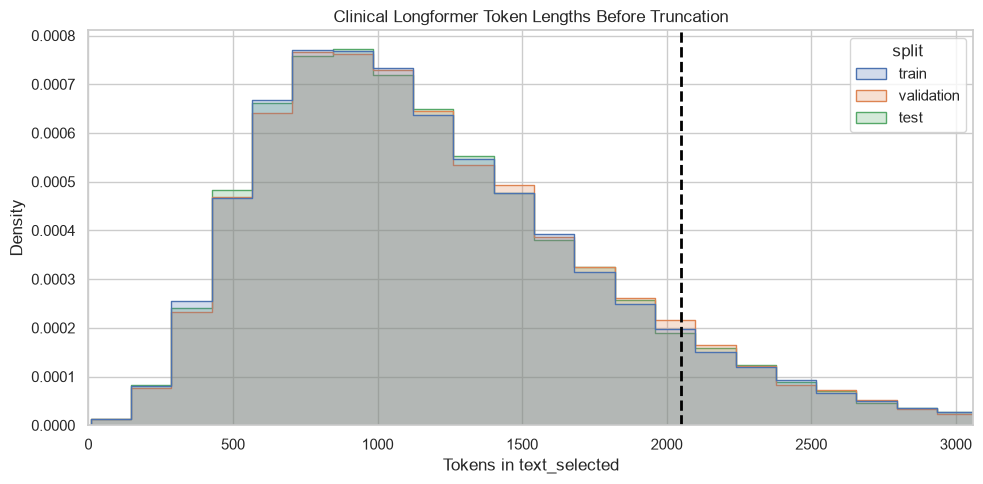

In [50]:
# ============================================================
# CELL 12 - PLOT THE TOKEN-LENGTH DISTRIBUTIONS
# ============================================================

token_plot_data = pd.concat(
    [
        split_frames[name][["longformer_token_count"]].assign(split=name)
        for name in SPLIT_ORDER
    ],
    ignore_index=True,
)
plot_upper_limit = max(
    MAX_LENGTH,
    int(token_plot_data["longformer_token_count"].quantile(0.99)),
)
plt.figure(figsize=(10, 5))
sns.histplot(
    data=token_plot_data,
    x="longformer_token_count",
    hue="split",
    hue_order=SPLIT_ORDER,
    bins=50,
    element="step",
    stat="density",
    common_norm=False,
)
plt.axvline(MAX_LENGTH, color="black", linestyle="--", linewidth=2, label="Selected limit")
plt.xlim(0, plot_upper_limit)
plt.title("Clinical Longformer Token Lengths Before Truncation")
plt.xlabel(f"Tokens in {TEXT_COLUMN}")
plt.ylabel("Density")
plt.tight_layout()
token_length_plot_path = FIGURE_DIR / "token_length_distribution.png"
plt.savefig(token_length_plot_path, dpi=200, bbox_inches="tight")
plt.show()


### Representative text examples from each split

For a text-classification project, the equivalent of displaying sample images is to display representative note previews. The cell below shows five reproducible examples from each working split, including both classes where available. It displays only a shortened preview; the complete `model_text` remains unchanged and is still used for tokenisation.


In [51]:
# ============================================================
# CELL 12A - DISPLAY FIVE REPRESENTATIVE RECORDS PER SPLIT
# ============================================================

def select_balanced_examples(frame, sample_size, random_state):
    requested_by_label = {0: (sample_size + 1) // 2, 1: sample_size // 2}
    selected_parts = []

    for label_value, requested_count in requested_by_label.items():
        class_rows = frame.loc[frame["label"].eq(label_value)]
        selected_parts.append(
            class_rows.sample(
                n=min(requested_count, len(class_rows)),
                random_state=random_state + label_value,
            )
        )

    selected = pd.concat(selected_parts)
    if len(selected) < min(sample_size, len(frame)):
        remaining = frame.drop(index=selected.index)
        additional_count = min(sample_size - len(selected), len(remaining))
        selected = pd.concat(
            [selected, remaining.sample(n=additional_count, random_state=random_state + 10)]
        )

    return selected.sample(frac=1.0, random_state=random_state).reset_index(drop=True)

for split_position, split_name in enumerate(SPLIT_ORDER):
    example_records = select_balanced_examples(
        frame=split_frames[split_name],
        sample_size=EXAMPLE_RECORDS_PER_SPLIT,
        random_state=SEED + split_position,
    )
    example_records["label_name"] = example_records["label"].map(
        {0: f"no_{TASK_NAME}", 1: TASK_NAME}
    )
    example_records["text_preview"] = (
        example_records["model_text"]
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.slice(0, 500)
    )

    preview_columns = [
        "subject_id",
        "hadm_id",
        "label",
        "label_name",
        "longformer_token_count",
        "requires_truncation",
        "text_preview",
    ]
    print(f"{split_name.title()} split — {len(example_records)} representative records")
    with pd.option_context("display.max_colwidth", 500):
        display(example_records[preview_columns])


Train split — 5 representative records


,subject_id,hadm_id,label,label_name,longformer_token_count,requires_truncation,text_preview
0,10847927,27379485,0,no_depression,764,False,"past medical history: HTN AAA h/o CVA, no residual effects s/p 6 x C-sections chief complaint: shortness of breath, dyspnea on exertion medications on admission: 1. Ferrous Sulfate 325 mg daily 2. Gabapentin 100 mg QHS 3. Metoprolol tartrate 12.5 mg BID 4. Pantoprazle 40 mg daily 5. Simvastatin 40 mg daily 6. Calcium+Vit D 7. Vitamin C 500 mg daily 8. Centrum Silver discharge medications: 1. Ferrous Sulfate 325 mg (65 mg Iron) Tablet Sig: One (1) Tablet PO DAILY (Daily). 2. Gabapentin 100 mg..."
1,13220594,27216673,1,depression,530,False,"past medical history: 1. Insulin-dependent diabetes. 2. Hyperlipidemia. 3. Hypertension. 4. Peripheral neuropathy, feet up to ankles. 5. Seasonal allergies. 6. Atopic dermatitis. 7. Lumbosacral radiculopathy. 8. [MASK]. chief complaint: Admitted for C3 of RICE chemotherapy history of present illness: [DEID] yo male with a history of DLBCL who is admitted for cycle 3 R-ICE. The patient states he has been feeling overall well. He has had some generalized malaise. He denies any recent fevers, c..."
2,12235296,28435507,0,no_depression,1154,False,past medical history: 1. Coronary artery disease - MI x3 with her first MI at age [DEID]. The patient underwent a CABG in [DEID]. Status post LAD drug-eluting stent in [DEID]. She is followed by Dr. [DEID]. 2. Peripheral vascular disease status post angioplasty of the right leg - [DEID] 3. Chronic kidney disease 4. Renal artery stenosis status post right renal artery stent- [DEID] 5. Carotid stenosis status post left internal carotid stent- [DEID]. 6. Gout 7. Polymyalgia rheumatica 8. Hypert...
3,11651096,20624211,0,no_depression,964,False,"past medical history: - Hyperlipidemia - BPH - Chronic venous insufficiency, left leg since age [DEID]. - Obesity. (per Atrius records also) - Borderline Hypothyroidism - ONYCHOMYCOSIS - STASIS ULCER - BUNDLE BRANCH BLOCK - RIGHT - SLEEP APNEA - POSTPHLEBITIC SYNDROME - DIVERTICULOSIS chief complaint: double vision history of present illness: History of Present Illness (per Dr. [DEID]: [DEID] is a [DEID] yo right handed man who presents for evaluation of an episode of double vision. The pati..."
4,10266157,27281159,1,depression,938,False,"past medical history: 1. [MASK], PTSD, borderline personality disorder (has required Psychiatric hospitalization at [DEID] [DEID]) 2. Somatization disorder 3. Hypothyroidism (s/p thyroidectomy in [DEID] 4. Hypoparathyroidism (post-surgical), hypocalciuria 5. Anal squamous cell carcinoma (in remission) 6. Colonic diverticulosis, colonic polyps (adenomatous) 7. History of pancreatitis 8. History of ischemic colitis (symptomatic treatment, [DEID] 9. s/p hysterectomy (menorrhagia treatment) chie..."


Validation split — 5 representative records


,subject_id,hadm_id,label,label_name,longformer_token_count,requires_truncation,text_preview
0,12980551,20540758,1,depression,1114,False,"past medical history: HTN Hyperdipidemia Coronary artery disease Gastroesophageal reflux disease Chronic kidney diseas - Wegener's granulomatosis [MASK], currently working with counselor bimonthly Appendectomy Hernia repair in his 20s. Leg cramps Anemia chief complaint: Chest Pain history of present illness: [DEID] M with hx CAD s/p CABG (LIMA-LAD, SVG-OM, SVG-diag, SVG-PDA [DEID], inferior MI in [DEID], stent of LCx and [DEID] RCA in [DEID] (cath showed occluded SVG-Diag and RPDA at that t..."
1,16030251,20451295,0,no_depression,771,False,"past medical history: Seasonal allergies; sleep apnea; in [DEID], he had a cerebral bleed, which was found to be results of cerebral amyloid angiopathy and he is followed at [DEID] for that. As part of several studies, he has had PET scans in the past. chief complaint: Right thigh myxoma history of present illness: Mr. [DEID] is a very pleasant [DEID] gentleman who has noticed this mass in his right thigh last [DEID]. It became smaller and so he did not think much of it as it almost really w..."
2,11167081,21729098,0,no_depression,1116,False,"past medical history: - CABG [DEID] - Coronary artery disease - Non-Q wave Myocardial Infarction x 2 in [DEID] s/p cath [DEID] with non-flow limiting CAD - Hypertension - Dyslipidemia - Diabetes Mellitus type 2 - Sleep Apnea (C-PAP) - Obesity - Memory Loss - Arthritis - Neuropathy - TIAs no residual, presented as diplopia and resolved after <1hr - Hemorrhoids chief complaint: Abnormal visual changes history of present illness: [DEID] year old male with a history of CAD s/p MI in [DEID] and C..."
3,19977310,24644456,0,no_depression,884,False,"past medical history: -ESRD [DEID] diabetic nephropathy and hypertensive nephrosclerosis; started HD [DEID] -GCA -Hypertension -Hyperlipidemia -COPD -Diabetes mellitus, on insulin -Gastroesophageal reflux disease -Anemia of chronic kidney disease -Hernia repair -Osteoarthritis -s/p right knee replacement -Dishydrotic eczema chief complaint: fever history of present illness: [DEID] year old male with history of ESRD on HD, DM, and HTN presents with fever at dialysis ([DEID] on the day of admi..."
4,16114059,21385888,1,depression,447,False,"past medical history: stage III melanoma (L arm, s/p excision with sentinal LN bx +) EtOH abuse HTN [MASK] chief complaint: Found down history of present illness: [DEID] hx etoh abuse, melanoma who was found down in her driveway by a neighbor this evening, [DEID] breathing. Her husband last saw her at 10am prior to leaving for work, states that she occassionally goes on etoh benders. EMS was called, noted agonal breathing and so intubated her in the field. Brought to [DEID] where core temper..."


Test split — 5 representative records


,subject_id,hadm_id,label,label_name,longformer_token_count,requires_truncation,text_preview
0,13235848,20871848,0,no_depression,1075,False,"past medical history: - afib not on anticoagulation since [DEID] secondary to gynecological bleed in setting of therapeutic INR. Was supposed to f/u with gyn for biopsy/clearance but never did. - HTN - HLD - cataracts chief complaint: Confusion, facial droop history of present illness: Ms. [DEID] is a [DEID] RH woman with history of afib not on coumadin, HTN and HLD who presented with confusion, L facial droop and listing to the left side this morning. Last well known time was 10 [DEID] befo..."
1,12501169,27937568,0,no_depression,1010,False,"past medical history: A. Fib, HTN, HLD, asthma, h/o pneumonia, TIA [DEID], fx C1-C2 (cannot lie flat), spinal stenosis, goiter, obesity, osteopenia chief complaint: left knee pain and wound opening history of present illness: [DEID] female presents with a wound dehiscence s/p mechanical fall. Patient is a [DEID] female with a past medical history of left knee osteoarthritis who is status post left TKA with Dr. [DEID] on [DEID], atrial fibrillation (on Eliquis), hypertension, hyperlipidemia w..."
2,12240787,20862660,0,no_depression,1280,False,"past medical history: Post intubation tracheal stenosis s/p tracheostomy CLL under surveillance, not treated NSCLC, squamous s/p resection [DEID] Right femur fracture [DEID] Right hip fracture [DEID] Bilateral PNA resulting in respiratory failure Arthritis Afib on lovenox h/o MI x [DEID] s/p back surgery x 2 Decubitous ulcers chief complaint: Dyspnea, increased secretions history of present illness: [DEID] year-old lady with a history of CLL w/ pleural effusion, h/o tracheal stenosis, [DEID]..."
3,16896839,20181505,1,depression,1207,False,"past medical history: DM2 HTN GERD HLD [MASK] s/p cholecystectomy chief complaint: VISUAL LOSS- CODE STROKE CALLED. history of present illness: Ms. [DEID] is a [DEID] yo woman with DM, HTN, HLD and recent admission earlier this month for posterior circulation strokes primarily in L occipital lobe who presented with visual symptoms. Around noon the patient was upset with her husband and went upstairs. She started seeing white clouds in her vision that lasted anywhere from 10 minutes to 2.5 ho..."
4,12440965,21375947,1,depression,1952,False,"past medical history: 1. CARDIAC RISK FACTORS: +hypertension, +dyslipidemia, +diabetes - ESRD [DEID] DM -- s/p transplant [DEID] (on Pred/myfortic) -- transplant-related DVT s/p IVC filter - [DEID] (EF 55%) - CAD s/p stents to LAD, LCx - DM2 c/b nephropathy, CAD - HTN - HLD - COPD - CVA - PVD - Pulmonary hypertension - Aortic stenosis - Lower GI bleed - Gastritis - Lung nodules - C. difficile colitis - Glaucoma - prostate CA chief complaint: Genital wounds history of present illness: [DEID] ..."


## 5. Tokenise and create dynamic batches

Clinical Longformer performs these model-specific transformations:

1. convert text to byte-pair token IDs and add special tokens;
2. truncate only above the configured 2,048-token limit;
3. dynamically pad to a multiple of the 512-token attention window;
4. create the ordinary attention mask;
5. create a global-attention mask with global attention on the first `<s>` token.

The original Parquet files and text fields are not modified.


In [52]:
# ============================================================
# CELL 13 - CONVERT PANDAS SPLITS TO HUGGING FACE DATASETS
# ============================================================

raw_datasets = DatasetDict(
    {
        split_name: Dataset.from_pandas(
            split_frames[split_name][["model_text", "label"]], preserve_index=False
        )
        for split_name in SPLIT_ORDER
    }
)
print(raw_datasets)


DatasetDict({
    train: Dataset({
        features: ['model_text', 'label'],
        num_rows: 126226
    })
    validation: Dataset({
        features: ['model_text', 'label'],
        num_rows: 27238
    })
    test: Dataset({
        features: ['model_text', 'label'],
        num_rows: 26782
    })
})


In [53]:
# ============================================================
# CELL 14 - TOKENISE AND TRUNCATE THE MODEL INPUTS
# ============================================================

def tokenise_batch(batch):
    tokenised_batch = tokenizer(
        batch["model_text"], truncation=True, max_length=MAX_LENGTH, padding=False
    )
    tokenised_batch["labels"] = batch["label"]
    return tokenised_batch

tokenised_datasets = DatasetDict()
for split_name in SPLIT_ORDER:
    tokenised_split = raw_datasets[split_name].map(
        tokenise_batch,
        batched=True,
        remove_columns=raw_datasets[split_name].column_names,
        desc=(f"Tokenising {split_name} data"),
    )
    tokenised_datasets[split_name] = tokenised_split
    maximum_encoded_length = max(len(input_ids) for input_ids in tokenised_split["input_ids"])
    if maximum_encoded_length > MAX_LENGTH:
        raise ValueError(f"A {split_name} input exceeds " f"the {MAX_LENGTH}-token limit.")

    print(
        f"{split_name}: "
        f"{len(tokenised_split):,} examples; "
        f"maximum encoded length = "
        f"{maximum_encoded_length}"
    )


Tokenising train data: 100%|██████████| 126226/126226 [02:14<00:00, 939.33 examples/s]


train: 126,226 examples; maximum encoded length = 2048


Tokenising validation data: 100%|██████████| 27238/27238 [00:29<00:00, 921.49 examples/s]


validation: 27,238 examples; maximum encoded length = 2048


Tokenising test data: 100%|██████████| 26782/26782 [00:29<00:00, 921.21 examples/s]


test: 26,782 examples; maximum encoded length = 2048


In [54]:
# ============================================================
# CELL 15 - CREATE LONGFORMER BATCHES AND DATA LOADERS
# ============================================================

class LongformerClassificationCollator:
    def __init__(self, tokenizer_object, pad_to_multiple_of):
        self.base_collator = DataCollatorWithPadding(
            tokenizer=tokenizer_object,
            padding=True,
            pad_to_multiple_of=pad_to_multiple_of,
            return_tensors="pt",
        )

    def __call__(self, features):
        batch = self.base_collator(features)
        global_attention_mask = torch.zeros_like(batch["attention_mask"])
        global_attention_mask[:, 0] = 1
        batch["global_attention_mask"] = global_attention_mask
        return batch

PAD_TO_MULTIPLE_OF = LONGFORMER_ATTENTION_WINDOW
data_collator = LongformerClassificationCollator(
    tokenizer_object=tokenizer,
    pad_to_multiple_of=PAD_TO_MULTIPLE_OF,
)
data_loader_generator = torch.Generator().manual_seed(SEED)
loader_options = {
    "collate_fn": data_collator,
    "num_workers": 0,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(
    tokenised_datasets["train"],
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=data_loader_generator,
    **loader_options,
)
validation_loader = DataLoader(
    tokenised_datasets["validation"],
    batch_size=EVALUATION_BATCH_SIZE,
    shuffle=False,
    **loader_options,
)
test_loader = DataLoader(
    tokenised_datasets["test"],
    batch_size=EVALUATION_BATCH_SIZE,
    shuffle=False,
    **loader_options,
)
example_batch = next(iter(train_loader))
print("Example dynamically padded batch:")
for field_name, field_value in example_batch.items():
    print(field_name, tuple(field_value.shape))
print("Global-attention tokens per example:", example_batch["global_attention_mask"].sum(dim=1).tolist())


Example dynamically padded batch:
input_ids (1, 1024)
attention_mask (1, 1024)
labels (1,)
global_attention_mask (1, 1024)
Global-attention tokens per example: [1]


## 6. Address class imbalance and load the frozen-encoder Clinical Longformer baseline

Class weights are calculated from admission-level training labels only. Validation and test labels do not influence them. `yikuan8/Clinical-Longformer` is loaded with a new binary classification head. Every pretrained `longformer` parameter is frozen, while the complete classification head remains trainable.

This is a **frozen-encoder baseline**, not full-model fine-tuning. Gradient checkpointing is disabled because the frozen encoder requires no backward activation graph.

In [55]:
# ============================================================
# CELL 16 - CALCULATE TRAINING-ONLY CLASS WEIGHTS
# ============================================================

training_labels = split_frames["train"]["label"].to_numpy(dtype=int)
class_weight_values = compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1]), y=training_labels
)
CLASS_WEIGHTS = torch.tensor(class_weight_values, dtype=torch.float32, device=DEVICE)
class_weight_table = pd.DataFrame(
    {
        "label": [0, 1],
        "training_count": [int((training_labels == 0).sum()), int((training_labels == 1).sum())],
        "class_weight": class_weight_values,
    }
)
display(class_weight_table)


,label,training_count,class_weight
0,0,104051,0.606558
1,1,22175,2.846133


In [56]:
# ============================================================
# CELL 17 - LOAD AND FREEZE CLINICAL LONGFORMER
# ============================================================

ID_TO_LABEL = {0: f"no_{TASK_NAME}", 1: TASK_NAME}
LABEL_TO_ID = {name: label_id for label_id, name in ID_TO_LABEL.items()}
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=ID_TO_LABEL,
    label2id=LABEL_TO_ID,
    cache_dir=str(MODEL_CACHE_DIR),
)
model.config.problem_type = "single_label_classification"
if hasattr(model.config, "use_cache"):
    model.config.use_cache = False

# Freeze the complete pretrained Clinical Longformer encoder.
for parameter in model.longformer.parameters():
    parameter.requires_grad = False

# Train the entire task-specific classification head (dense + output layer).
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

unexpected_trainable_parameters = [
    parameter_name
    for parameter_name, parameter in model.named_parameters()
    if parameter.requires_grad and not parameter_name.startswith("classifier.")
]
if unexpected_trainable_parameters:
    raise ValueError(
        "Unexpected trainable parameters were found: "
        f"{unexpected_trainable_parameters[:10]}"
    )

model.to(device=DEVICE, dtype=torch.float32)
model_parameter_dtypes = {parameter.dtype for parameter in model.parameters()}
if model_parameter_dtypes != {torch.float32}:
    raise TypeError(f"Expected float32 model parameters, found {model_parameter_dtypes}.")
if MAX_LENGTH > tokenizer.model_max_length:
    raise ValueError("MAX_LENGTH exceeds the tokenizer's supported context length.")
if MAX_LENGTH > model.config.max_position_embeddings - 2:
    raise ValueError("MAX_LENGTH exceeds the model's supported context length.")

configured_attention_windows = model.config.attention_window
if isinstance(configured_attention_windows, int):
    configured_attention_windows = [configured_attention_windows]
if max(configured_attention_windows) != LONGFORMER_ATTENTION_WINDOW:
    raise ValueError(
        "LONGFORMER_ATTENTION_WINDOW does not match the loaded model configuration."
    )

total_parameter_count = sum(parameter.numel() for parameter in model.parameters())
trainable_parameter_count = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
frozen_parameter_count = total_parameter_count - trainable_parameter_count
trainable_percentage = trainable_parameter_count / total_parameter_count * 100

print("Model class:", model.__class__.__name__)
print("Training strategy:", TRAINING_STRATEGY)
print("Model parameter dtype:", next(model.parameters()).dtype)
print("Maximum supported tokens:", model.config.max_position_embeddings - 2)
print("Attention window:", sorted(set(configured_attention_windows)))
print("Gradient checkpointing:", model.is_gradient_checkpointing)
print("Total parameters:", f"{total_parameter_count:,}")
print("Frozen pretrained parameters:", f"{frozen_parameter_count:,}")
print("Trainable classification-head parameters:", f"{trainable_parameter_count:,}")
print("Trainable percentage:", f"{trainable_percentage:.4f}%")
print("Trainable parameter tensors:")
for parameter_name, parameter in model.named_parameters():
    if parameter.requires_grad:
        print("-", parameter_name, tuple(parameter.shape))
print(
    "\nWarnings about newly initialized classification weights are expected "
    "because this task head is trained by the baseline."
)

Loading weights: 100%|██████████| 269/269 [00:00<00:00, 12883.00it/s]
[transformers] LongformerForSequenceClassification LOAD REPORT from: yikuan8/Clinical-Longformer
Key                                | Status     | 
-----------------------------------+------------+-
lm_head.layer_norm.weight          | UNEXPECTED | 
lm_head.bias                       | UNEXPECTED | 
longformer.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight               | UNEXPECTED | 
lm_head.decoder.bias               | UNEXPECTED | 
lm_head.layer_norm.bias            | UNEXPECTED | 
lm_head.decoder.weight             | UNEXPECTED | 
lm_head.dense.bias                 | UNEXPECTED | 
classifier.dense.weight            | MISSING    | 
classifier.dense.bias              | MISSING    | 
classifier.out_proj.bias           | MISSING    | 
classifier.out_proj.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch

Model class: LongformerForSequenceClassification
Training strategy: frozen_encoder_classification_head_only
Model parameter dtype: torch.float32
Maximum supported tokens: 4096
Attention window: [512]
Gradient checkpointing: False
Total parameters: 148,660,994
Frozen pretrained parameters: 148,068,864
Trainable classification-head parameters: 592,130
Trainable percentage: 0.3983%
Trainable parameter tensors:
- classifier.dense.weight (768, 768)
- classifier.dense.bias (768,)
- classifier.out_proj.weight (2, 768)
- classifier.out_proj.bias (2,)

Warnings about newly initialized classification weights are expected because this task head is trained by the baseline.


### Clinical Longformer baseline construction in one place

The following cell consolidates the model configuration, complete PyTorch module structure, component-level parameter counts and encoder-layer parameter counts. Every pretrained Clinical Longformer encoder layer should show zero trainable parameters, while the classification head remains trainable.

In [57]:
# ============================================================
# CELL 17A - DISPLAY MODEL CONSTRUCTION AND LAYER SUMMARY
# ============================================================

base_model = getattr(model, model.base_model_prefix)
encoder_layers = base_model.encoder.layer

model_configuration = pd.DataFrame(
    {
        "property": [
            "Model class",
            "Base-model prefix",
            "Vocabulary size",
            "Hidden size",
            "Transformer encoder layers",
            "Attention heads per layer",
            "Intermediate feed-forward size",
            "Maximum position embeddings",
            "Hidden dropout probability",
            "Attention dropout probability",
            "Output labels",
            "Total parameters",
            "Trainable parameters",
            "Frozen parameters",
        ],
        "value": [
            model.__class__.__name__,
            model.base_model_prefix,
            model.config.vocab_size,
            model.config.hidden_size,
            model.config.num_hidden_layers,
            model.config.num_attention_heads,
            model.config.intermediate_size,
            model.config.max_position_embeddings,
            model.config.hidden_dropout_prob,
            model.config.attention_probs_dropout_prob,
            model.config.num_labels,
            f"{total_parameter_count:,}",
            f"{trainable_parameter_count:,}",
            f"{total_parameter_count - trainable_parameter_count:,}",
        ],
    }
)
display(model_configuration)

component_parameter_rows = []
for component_name, component in model.named_children():
    component_parameter_rows.append(
        {
            "component": component_name,
            "module_type": component.__class__.__name__,
            "parameters": sum(parameter.numel() for parameter in component.parameters()),
            "trainable_parameters": sum(
                parameter.numel()
                for parameter in component.parameters()
                if parameter.requires_grad
            ),
        }
    )

print("Top-level components:")
display(pd.DataFrame(component_parameter_rows))

encoder_layer_rows = []
for layer_number, encoder_layer in enumerate(encoder_layers, start=1):
    encoder_layer_rows.append(
        {
            "encoder_layer": layer_number,
            "parameters": sum(parameter.numel() for parameter in encoder_layer.parameters()),
            "trainable_parameters": sum(
                parameter.numel()
                for parameter in encoder_layer.parameters()
                if parameter.requires_grad
            ),
        }
    )

print("Transformer encoder layers:")
display(pd.DataFrame(encoder_layer_rows))

# Capture the output shape of every leaf module with one example.
layer_summary_rows = []
summary_hooks = []

def format_output_shape(output_value):
    if isinstance(output_value, torch.Tensor):
        return str(tuple(output_value.shape))
    if isinstance(output_value, (tuple, list)):
        return str(
            [tuple(value.shape) for value in output_value if isinstance(value, torch.Tensor)]
        )
    return type(output_value).__name__

def make_summary_hook(module_name):
    def summary_hook(module, inputs, output):
        direct_parameters = list(module.parameters(recurse=False))
        layer_summary_rows.append(
            {
                "layer": module_name,
                "module_type": module.__class__.__name__,
                "output_shape": format_output_shape(output),
                "parameters": sum(parameter.numel() for parameter in direct_parameters),
                "trainable_parameters": sum(
                    parameter.numel() for parameter in direct_parameters if parameter.requires_grad
                ),
            }
        )
    return summary_hook

for module_name, module in model.named_modules():
    if module_name and not any(module.children()):
        summary_hooks.append(module.register_forward_hook(make_summary_hook(module_name)))

summary_batch = {
    field_name: field_value[:1].to(DEVICE)
    for field_name, field_value in example_batch.items()
    if field_name != "labels"
}
model.eval()
with torch.no_grad():
    model(**summary_batch)

for hook in summary_hooks:
    hook.remove()

layer_summary_table = pd.DataFrame(layer_summary_rows)
print(f"Leaf-module summary ({len(layer_summary_table)} executed modules):")
display(
    HTML(
        '<div style="max-height: 600px; overflow: auto; border: 1px solid #bbb; '
        'padding: 6px;">'
        + layer_summary_table.to_html(index=False)
        + "</div>"
    )
)

print("Complete PyTorch construction (expand and scroll):")
display(
    HTML(
        '<details><summary>Open complete model construction</summary>'
        '<div style="max-height: 600px; overflow: auto; border: 1px solid #bbb; '
        'padding: 10px;"><pre>'
        + html.escape(str(model))
        + "</pre></div></details>"
    )
)


,property,value
0,Model class,LongformerForSequenceClassification
1,Base-model prefix,longformer
2,Vocabulary size,50265
3,Hidden size,768
4,Transformer encoder layers,12
5,Attention heads per layer,12
6,Intermediate feed-forward size,3072
7,Maximum position embeddings,4098
8,Hidden dropout probability,0.1
9,Attention dropout probability,0.1


Top-level components:


,component,module_type,parameters,trainable_parameters
0,longformer,LongformerModel,148068864,0
1,classifier,LongformerClassificationHead,592130,592130


Transformer encoder layers:


,encoder_layer,parameters,trainable_parameters
0,1,8859648,0
1,2,8859648,0
2,3,8859648,0
3,4,8859648,0
4,5,8859648,0
5,6,8859648,0
6,7,8859648,0
7,8,8859648,0
8,9,8859648,0
9,10,8859648,0


Leaf-module summary (177 executed modules):


layer,module_type,output_shape,parameters,trainable_parameters
longformer.embeddings.word_embeddings,Embedding,"(1, 1024, 768)",38603520,0
longformer.embeddings.position_embeddings,Embedding,"(1, 1024, 768)",3147264,0
longformer.embeddings.token_type_embeddings,Embedding,"(1, 1024, 768)",768,0
longformer.embeddings.LayerNorm,LayerNorm,"(1, 1024, 768)",1536,0
longformer.embeddings.dropout,Dropout,"(1, 1024, 768)",0,0
longformer.encoder.layer.0.attention.self.query,Linear,"(1024, 1, 768)",590592,0
longformer.encoder.layer.0.attention.self.key,Linear,"(1024, 1, 768)",590592,0
longformer.encoder.layer.0.attention.self.value,Linear,"(1024, 1, 768)",590592,0
longformer.encoder.layer.0.attention.self.query_global,Linear,"(1, 1, 768)",590592,0
longformer.encoder.layer.0.attention.self.key_global,Linear,"(1024, 1, 768)",590592,0


Complete PyTorch construction (expand and scroll):


In [58]:
# ============================================================
# CELL 18 - VERIFY ONE FORWARD PASS
# ============================================================

forward_batch = {
    field_name: field_value.to(DEVICE)
    for field_name, field_value in example_batch.items()
}
forward_labels = forward_batch.pop("labels")

model.eval()
with torch.no_grad():
    forward_outputs = model(**forward_batch)
    forward_logits = forward_outputs.logits
    forward_loss_weights = CLASS_WEIGHTS.to(
        device=forward_logits.device,
        dtype=torch.float32,
    )
    forward_loss = F.cross_entropy(
        forward_logits.float(),
        forward_labels.long(),
        weight=forward_loss_weights,
    )

if forward_logits.shape != (len(forward_labels), 2):
    raise ValueError("The model returned an unexpected logits shape.")

if not torch.isfinite(forward_loss):
    raise ValueError("The forward-pass loss is not finite.")

print("Logits dtype:", forward_logits.dtype)
print("Loss-calculation dtype:", forward_loss.dtype)
print("Forward-pass logits shape:", tuple(forward_logits.shape))
print("Weighted loss:", round(forward_loss.item(), 6))
print("Clinical Longformer forward-pass test passed.")


Logits dtype: torch.float32
Loss-calculation dtype: torch.float32
Forward-pass logits shape: (1, 2)
Weighted loss: 0.569405
Clinical Longformer forward-pass test passed.


### Capture pre-training weights for frozen-encoder verification

Before optimisation, this section fingerprints **every model parameter tensor** and stores exact CPU copies of representative pretrained and classification-head tensors. After training, the notebook verifies that token embeddings and early/middle/final encoder layers remained exactly unchanged while both classification-head layers changed.

In [59]:
# ============================================================
# CELL 18A - CAPTURE PRE-TRAINING PARAMETER VALUES
# ============================================================

def calculate_parameter_fingerprint(parameter):
    parameter_bytes = (
        parameter.detach().cpu().contiguous().view(torch.uint8).numpy().tobytes()
    )
    return hashlib.sha256(parameter_bytes).hexdigest()


named_parameters_before_training = dict(model.named_parameters())
representative_parameter_roles = {
    "token_embeddings": "longformer.embeddings.word_embeddings.weight",
    "encoder_layer_1_attention": "longformer.encoder.layer.0.attention.self.query.weight",
    "encoder_layer_6_output": "longformer.encoder.layer.5.output.dense.weight",
    "encoder_layer_12_output": "longformer.encoder.layer.11.output.dense.weight",
    "classification_dense": "classifier.dense.weight",
    "classification_output": "classifier.out_proj.weight",
}
missing_parameters = [
    name for name in representative_parameter_roles.values()
    if name not in named_parameters_before_training
]
if missing_parameters:
    raise KeyError(
        "Could not find expected Clinical Longformer parameters: "
        f"{missing_parameters}"
    )

print("Fingerprinting every model parameter tensor before training...")
initial_parameter_fingerprints = {
    name: calculate_parameter_fingerprint(parameter)
    for name, parameter in tqdm(
        named_parameters_before_training.items(),
        desc="Pre-training fingerprints",
        unit="tensor",
    )
}
initial_parameter_snapshots = {
    role: named_parameters_before_training[name].detach().cpu().clone()
    for role, name in representative_parameter_roles.items()
}
pretraining_parameter_table = pd.DataFrame(
    [
        {
            "role": role,
            "parameter": name,
            "shape": str(tuple(named_parameters_before_training[name].shape)),
            "values": named_parameters_before_training[name].numel(),
            "requires_grad": named_parameters_before_training[name].requires_grad,
        }
        for role, name in representative_parameter_roles.items()
    ]
)
display(pretraining_parameter_table)
print("All parameter tensors fingerprinted:", len(initial_parameter_fingerprints))
print("Exact representative snapshots stored on CPU:", len(initial_parameter_snapshots))

Fingerprinting every model parameter tensor before training...


Pre-training fingerprints: 100%|██████████| 273/273 [00:01<00:00, 137.54tensor/s]


,role,parameter,shape,values,requires_grad
0,token_embeddings,longformer.embeddings.word_embeddings.weight,"(50265, 768)",38603520,False
1,encoder_layer_1_attention,longformer.encoder.layer.0.attention.self.query.weight,"(768, 768)",589824,False
2,encoder_layer_6_output,longformer.encoder.layer.5.output.dense.weight,"(768, 3072)",2359296,False
3,encoder_layer_12_output,longformer.encoder.layer.11.output.dense.weight,"(768, 3072)",2359296,False
4,classification_dense,classifier.dense.weight,"(768, 768)",589824,True
5,classification_output,classifier.out_proj.weight,"(2, 768)",1536,True


All parameter tensors fingerprinted: 273
Exact representative snapshots stored on CPU: 6


## 7. Define evaluation and threshold-selection functions

Because the positive class is imbalanced, the notebook reports both conventional classification metrics and ranking metrics:

- accuracy and balanced accuracy;
- precision, recall, F1, and specificity;
- ROC-AUC;
- PR-AUC (average precision).

The validation threshold is chosen to maximise validation F1. That threshold is then frozen and applied unchanged to the test probabilities.


In [60]:
# ============================================================
# CELL 19 - DEFINE CLASSIFICATION METRICS
# ============================================================

def safe_auc_score(score_function, labels, probabilities):
    if len(np.unique(labels)) < 2:
        return float("nan")

    return float(score_function(labels, probabilities))

def calculate_classification_metrics(labels, positive_probabilities, threshold):
    labels = np.asarray(labels, dtype=int)
    positive_probabilities = np.asarray(positive_probabilities, dtype=float)
    if not np.isfinite(positive_probabilities).all():
        non_finite_count = int((~np.isfinite(positive_probabilities)).sum())
        raise FloatingPointError(
            f"Found {non_finite_count} non-finite prediction probabilities. "
            "Restart the kernel and rerun from Cell 1 so the model is loaded "
            "again with float32 parameters."
        )
    predictions = (positive_probabilities >= threshold).astype(int)
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()
    specificity_denominator = true_negative + false_positive
    specificity = (
        true_negative / specificity_denominator if specificity_denominator > 0 else float("nan")
    )
    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(specificity),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": safe_auc_score(roc_auc_score, labels, positive_probabilities),
        "pr_auc": safe_auc_score(average_precision_score, labels, positive_probabilities),
        "true_negative": int(true_negative),
        "false_positive": int(false_positive),
        "false_negative": int(false_negative),
        "true_positive": int(true_positive),
    }


In [61]:
# ============================================================
# CELL 20 - DEFINE VALIDATION THRESHOLD SELECTION
# ============================================================

def select_f1_threshold(labels, positive_probabilities):
    precision_values, recall_values, threshold_values = precision_recall_curve(
        labels, positive_probabilities
    )
    if len(threshold_values) == 0:
        return 0.5, float("nan"), pd.DataFrame()

    precision_for_thresholds = precision_values[:-1]
    recall_for_thresholds = recall_values[:-1]
    f1_values = (
        2
        * precision_for_thresholds
        * recall_for_thresholds
        / np.clip(precision_for_thresholds + recall_for_thresholds, a_min=1e-12, a_max=None)
    )
    best_position = int(np.nanargmax(f1_values))
    threshold_table = pd.DataFrame(
        {
            "threshold": threshold_values,
            "precision": precision_for_thresholds,
            "recall": recall_for_thresholds,
            "f1": f1_values,
        }
    )
    return (
        float(threshold_values[best_position]),
        float(f1_values[best_position]),
        threshold_table,
    )


In [62]:
# ============================================================
# CELL 21 - DEFINE MODEL EVALUATION
# ============================================================

PROGRESS_BAR_FORMAT = (
    "{desc}: {percentage:3.0f}%|{bar:32}| "
    "{n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}{postfix}]"
)

def prepare_weighted_loss_inputs(logits, labels, class_weights):
    """Use float32 for stable weighted cross-entropy under mixed precision."""
    labels_for_loss = labels.to(device=logits.device, dtype=torch.long)
    weights_for_loss = class_weights.to(
        device=logits.device,
        dtype=torch.float32,
    )
    return logits.float(), labels_for_loss, weights_for_loss

def evaluate_model(model_object, data_loader, class_weights, progress_description=None):
    model_object.eval()
    all_labels = []
    all_probabilities = []
    total_weighted_loss = 0.0
    total_class_weight = 0.0

    if progress_description is None:
        evaluation_batches = data_loader
    else:
        evaluation_batches = tqdm(
            data_loader,
            total=len(data_loader),
            desc=progress_description,
            leave=False,
            dynamic_ncols=True,
            unit="batch",
            bar_format=PROGRESS_BAR_FORMAT,
        )

    with torch.no_grad():
        for batch in evaluation_batches:
            labels = batch["labels"].to(DEVICE)
            model_inputs = {
                field_name: field_value.to(DEVICE)
                for field_name, field_value in batch.items()
                if field_name != "labels"
            }
            logits = model_object(**model_inputs).logits
            if not torch.isfinite(logits).all():
                raise FloatingPointError(
                    "The model produced NaN or infinite validation logits. "
                    "Restart the kernel and rerun from Cell 1."
                )
            logits_for_loss, labels_for_loss, weights_for_loss = (
                prepare_weighted_loss_inputs(
                    logits=logits,
                    labels=labels,
                    class_weights=class_weights,
                )
            )
            per_example_loss = F.cross_entropy(
                logits_for_loss,
                labels_for_loss,
                weight=weights_for_loss,
                reduction="none",
            )
            example_class_weights = weights_for_loss[labels_for_loss]
            total_weighted_loss += float(per_example_loss.sum().item())
            total_class_weight += float(example_class_weights.sum().item())
            positive_probabilities = torch.softmax(logits_for_loss, dim=-1)[:, 1]
            all_labels.extend(labels_for_loss.detach().cpu().numpy().tolist())
            all_probabilities.extend(
                positive_probabilities.detach().cpu().numpy().tolist()
            )

    mean_weighted_loss = total_weighted_loss / max(total_class_weight, 1e-12)
    return (
        mean_weighted_loss,
        np.asarray(all_labels, dtype=int),
        np.asarray(all_probabilities, dtype=float),
    )


## 8. Configure and train the frozen-encoder Clinical Longformer baseline

Only classification-head parameters are included in the optimiser. The pretrained Clinical Longformer encoder participates in each forward pass but receives no gradient updates. The best checkpoint is selected using validation PR-AUC because the positive class is imbalanced.

During each epoch, the progress bar displays batches, running loss, accuracy, learning rate, elapsed time and estimated remaining time. The test loader is not used by the training loop.

### Checkpoint and early-stopping policy

Validation PR-AUC is monitored after every epoch. By default, all requested epochs run, while the first patience-trigger epoch is recorded and optionally saved. The best-validation checkpoint remains the recommended model for test evaluation and deployment.

In [63]:
# ============================================================
# CELL 22 - CONFIGURE OPTIMISER AND LEARNING-RATE SCHEDULE
# ============================================================

optimizer = torch.optim.AdamW(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

trainable_parameter_ids = {
    id(parameter)
    for parameter in model.parameters()
    if parameter.requires_grad
}
optimizer_parameter_ids = {
    id(parameter)
    for parameter_group in optimizer.param_groups
    for parameter in parameter_group["params"]
}
missing_optimizer_parameter_count = len(
    trainable_parameter_ids - optimizer_parameter_ids
)

if missing_optimizer_parameter_count > 0:
    raise ValueError(
        f"{missing_optimizer_parameter_count} trainable parameters "
        "were not included in the optimiser."
    )

print("Verified: only trainable classification-head parameters are included in the optimiser.")
updates_per_epoch = max(1, math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS))
total_training_steps = updates_per_epoch * NUMBER_OF_EPOCHS
warmup_steps = int(round(total_training_steps * WARMUP_PROPORTION))
scheduler = get_linear_schedule_with_warmup(
    optimizer=optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_training_steps
)
AMP_ENABLED = bool(USE_MIXED_PRECISION and DEVICE.type == "cuda")
gradient_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)
training_schedule_table = pd.DataFrame(
    {
        "setting": [
            "Training batches per epoch",
            "Gradient accumulation steps",
            "Optimiser updates per epoch",
            "Total optimiser updates",
            "Warm-up updates",
            "Mixed precision",
        ],
        "value": [
            len(train_loader),
            GRADIENT_ACCUMULATION_STEPS,
            updates_per_epoch,
            total_training_steps,
            warmup_steps,
            AMP_ENABLED,
        ],
    }
)
display(training_schedule_table)


Verified: only trainable classification-head parameters are included in the optimiser.


,setting,value
0,Training batches per epoch,126226
1,Gradient accumulation steps,16
2,Optimiser updates per epoch,7890
3,Total optimiser updates,118350
4,Warm-up updates,11835
5,Mixed precision,True


In [64]:
# ============================================================
# CELL 23 - DEFINE ONE TRAINING EPOCH
# ============================================================

def format_duration(total_seconds):
    total_seconds = max(0, int(round(total_seconds)))
    hours, remainder = divmod(total_seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    if hours:
        return f"{hours:d}h {minutes:02d}m {seconds:02d}s"
    if minutes:
        return f"{minutes:d}m {seconds:02d}s"
    return f"{seconds:d}s"

def train_one_epoch(
    model_object,
    data_loader,
    optimizer_object,
    scheduler_object,
    class_weights,
    gradient_scaler_object,
    epoch_number,
    total_epochs,
):
    model_object.train()
    optimizer_object.zero_grad(set_to_none=True)
    total_weighted_loss = 0.0
    total_class_weight = 0.0
    correct_prediction_count = 0
    processed_example_count = 0
    skipped_optimizer_updates = 0
    training_start_time = time.time()

    print(f"\nEpoch {epoch_number}/{total_epochs}")
    progress_bar = tqdm(
        data_loader,
        total=len(data_loader),
        desc="Training",
        leave=True,
        dynamic_ncols=True,
        unit="batch",
        bar_format=PROGRESS_BAR_FORMAT,
    )

    for batch_position, batch in enumerate(progress_bar):
        labels = batch["labels"].to(DEVICE)
        model_inputs = {
            field_name: field_value.to(DEVICE)
            for field_name, field_value in batch.items()
            if field_name != "labels"
        }

        autocast_context = (
            torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=True,
            )
            if AMP_ENABLED
            else nullcontext()
        )
        with autocast_context:
            logits = model_object(**model_inputs).logits

        if not torch.isfinite(logits).all():
            raise FloatingPointError(
                f"Non-finite training logits occurred in batch {batch_position + 1}."
            )

        logits_for_loss, labels_for_loss, weights_for_loss = (
            prepare_weighted_loss_inputs(
                logits=logits,
                labels=labels,
                class_weights=class_weights,
            )
        )
        per_example_loss = F.cross_entropy(
            logits_for_loss,
            labels_for_loss,
            weight=weights_for_loss,
            reduction="none",
        )
        example_class_weights = weights_for_loss[labels_for_loss]
        batch_loss = (
            per_example_loss.sum()
            / example_class_weights.sum().clamp_min(1e-12)
        )
        if not torch.isfinite(batch_loss):
            raise FloatingPointError(
                f"Non-finite training loss occurred in batch {batch_position + 1}."
            )
        accumulation_loss = batch_loss / GRADIENT_ACCUMULATION_STEPS

        gradient_scaler_object.scale(accumulation_loss).backward()
        is_accumulation_boundary = (
            (batch_position + 1) % GRADIENT_ACCUMULATION_STEPS == 0
        )
        is_final_batch = batch_position + 1 == len(data_loader)

        if is_accumulation_boundary or is_final_batch:
            gradient_scaler_object.unscale_(optimizer_object)
            gradient_norm = clip_grad_norm_(
                model_object.parameters(),
                MAX_GRADIENT_NORM,
                error_if_nonfinite=False,
            )
            gradients_are_finite = bool(torch.isfinite(gradient_norm).item())

            if AMP_ENABLED:
                scale_before_update = gradient_scaler_object.get_scale()
                gradient_scaler_object.step(optimizer_object)
                gradient_scaler_object.update()
                optimizer_step_was_skipped = (
                    gradient_scaler_object.get_scale() < scale_before_update
                )
            else:
                if not gradients_are_finite:
                    raise FloatingPointError(
                        "Non-finite gradients occurred without CUDA AMP enabled."
                    )
                gradient_scaler_object.step(optimizer_object)
                gradient_scaler_object.update()
                optimizer_step_was_skipped = False

            if optimizer_step_was_skipped or not gradients_are_finite:
                skipped_optimizer_updates += 1
            else:
                scheduler_object.step()

            optimizer_object.zero_grad(set_to_none=True)

        batch_predictions = logits.argmax(dim=-1)
        correct_prediction_count += int(
            (batch_predictions == labels_for_loss).sum().item()
        )
        processed_example_count += int(labels_for_loss.size(0))
        total_weighted_loss += float(per_example_loss.detach().sum().item())
        total_class_weight += float(example_class_weights.detach().sum().item())

        running_loss = total_weighted_loss / max(total_class_weight, 1e-12)
        running_accuracy = correct_prediction_count / max(processed_example_count, 1)
        progress_bar.set_postfix(
            loss=f"{running_loss:.4f}",
            accuracy=f"{running_accuracy:.4f}",
            learning_rate=f"{scheduler_object.get_last_lr()[0]:.2e}",
            skipped_updates=skipped_optimizer_updates,
        )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    training_seconds = time.time() - training_start_time
    mean_training_loss = total_weighted_loss / max(total_class_weight, 1e-12)
    training_accuracy = correct_prediction_count / max(processed_example_count, 1)
    milliseconds_per_batch = training_seconds * 1_000 / max(len(data_loader), 1)

    if skipped_optimizer_updates:
        print(
            "CUDA AMP safely skipped",
            skipped_optimizer_updates,
            "non-finite optimiser update(s) and reduced its scale.",
        )

    return (
        mean_training_loss,
        training_accuracy,
        training_seconds,
        milliseconds_per_batch,
        skipped_optimizer_updates,
    )


In [65]:
# ============================================================
# CELL 24 - TRAIN AND SAVE BEST, SIGNAL AND FINAL CHECKPOINTS
# ============================================================

training_history_rows = []
best_validation_pr_auc = -float("inf")
best_epoch = None
early_stop_signal_epoch = None
last_completed_epoch = None
epochs_without_improvement = 0
training_start_time = time.time()

non_finite_parameter_names = [
    parameter_name
    for parameter_name, parameter in model.named_parameters()
    if not torch.isfinite(parameter).all()
]
if non_finite_parameter_names:
    raise FloatingPointError(
        "The current model already contains NaN or infinite parameters. "
        "Restart the kernel and run all cells from Cell 1 before training."
    )

for epoch_number in range(1, NUMBER_OF_EPOCHS + 1):
    epoch_start_time = time.time()
    (
        training_loss,
        training_accuracy,
        training_seconds,
        milliseconds_per_batch,
        skipped_optimizer_updates,
    ) = train_one_epoch(
        model_object=model,
        data_loader=train_loader,
        optimizer_object=optimizer,
        scheduler_object=scheduler,
        class_weights=CLASS_WEIGHTS,
        gradient_scaler_object=gradient_scaler,
        epoch_number=epoch_number,
        total_epochs=NUMBER_OF_EPOCHS,
    )

    validation_loss, validation_labels_for_epoch, validation_probabilities_for_epoch = (
        evaluate_model(
            model_object=model,
            data_loader=validation_loader,
            class_weights=CLASS_WEIGHTS,
            progress_description=f"Validating epoch {epoch_number}",
        )
    )
    validation_metrics_for_epoch = calculate_classification_metrics(
        labels=validation_labels_for_epoch,
        positive_probabilities=validation_probabilities_for_epoch,
        threshold=0.5,
    )
    validation_pr_auc = validation_metrics_for_epoch["pr_auc"]
    epoch_duration_seconds = time.time() - epoch_start_time
    last_completed_epoch = epoch_number

    epoch_result = {
        "epoch": epoch_number,
        "training_loss": training_loss,
        "training_accuracy": training_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_metrics_for_epoch["accuracy"],
        "validation_balanced_accuracy": validation_metrics_for_epoch["balanced_accuracy"],
        "validation_precision": validation_metrics_for_epoch["precision"],
        "validation_recall": validation_metrics_for_epoch["recall"],
        "validation_f1_at_0_5": validation_metrics_for_epoch["f1"],
        "validation_roc_auc": validation_metrics_for_epoch["roc_auc"],
        "validation_pr_auc": validation_pr_auc,
        "training_seconds": training_seconds,
        "milliseconds_per_batch": milliseconds_per_batch,
        "skipped_optimizer_updates": skipped_optimizer_updates,
        "epoch_seconds": epoch_duration_seconds,
    }
    training_history_rows.append(epoch_result)

    print(
        f"{len(train_loader)}/{len(train_loader)} - "
        f"{format_duration(epoch_duration_seconds)} - "
        f"{milliseconds_per_batch:.0f}ms/batch - "
        f"loss: {training_loss:.4f} - "
        f"accuracy: {training_accuracy:.4f} - "
        f"skipped_updates: {skipped_optimizer_updates} - "
        f"val_loss: {validation_loss:.4f} - "
        f"val_accuracy: {epoch_result['validation_accuracy']:.4f} - "
        f"val_f1: {epoch_result['validation_f1_at_0_5']:.4f} - "
        f"val_pr_auc: {validation_pr_auc:.4f}"
    )

    mean_epoch_seconds = np.mean([row["epoch_seconds"] for row in training_history_rows])
    maximum_remaining_epochs = NUMBER_OF_EPOCHS - epoch_number
    print(
        "Estimated maximum time remaining if all requested epochs run:",
        format_duration(mean_epoch_seconds * maximum_remaining_epochs),
    )

    validation_improved = (
        validation_pr_auc
        > best_validation_pr_auc + EARLY_STOPPING_MINIMUM_IMPROVEMENT
    )

    if validation_improved:
        best_validation_pr_auc = validation_pr_auc
        best_epoch = epoch_number
        epochs_without_improvement = 0
        model.save_pretrained(BEST_MODEL_DIR, safe_serialization=True)
        tokenizer.save_pretrained(BEST_MODEL_DIR)
        print("Saved a new best-validation checkpoint.")
    else:
        epochs_without_improvement += 1
        print(
            "Validation PR-AUC did not improve by at least "
            f"{EARLY_STOPPING_MINIMUM_IMPROVEMENT:g} "
            f"({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})."
        )

        patience_reached = epochs_without_improvement >= EARLY_STOPPING_PATIENCE
        if patience_reached and early_stop_signal_epoch is None:
            early_stop_signal_epoch = epoch_number

            if SAVE_EARLY_STOP_SIGNAL_MODEL:
                model.save_pretrained(
                    EARLY_STOP_SIGNAL_MODEL_DIR,
                    safe_serialization=True,
                )
                tokenizer.save_pretrained(EARLY_STOP_SIGNAL_MODEL_DIR)

            print(
                "Early-stopping patience was first reached at epoch",
                early_stop_signal_epoch,
            )
            print(
                "The best-validation model remains the checkpoint from epoch",
                best_epoch,
            )

            if STOP_TRAINING_WHEN_PATIENCE_REACHED:
                print("Training stopped because the stopping option is enabled.")
                break
            else:
                print("Training will continue because the stopping option is disabled.")

# Save the state from the last epoch that actually ran.
model.save_pretrained(FINAL_EPOCH_MODEL_DIR, safe_serialization=True)
tokenizer.save_pretrained(FINAL_EPOCH_MODEL_DIR)

total_training_seconds = time.time() - training_start_time
training_history = pd.DataFrame(training_history_rows)
training_history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("\nComplete epoch history:")
display(training_history.round(6))
print("Best-validation epoch:", best_epoch)
print("Best validation PR-AUC:", round(best_validation_pr_auc, 6))
print("Early-stop signal epoch:", early_stop_signal_epoch)
print("Last completed epoch:", last_completed_epoch)
print("Total training time:", format_duration(total_training_seconds))
print("\nSaved checkpoint meanings:")
print("Best validation model:", BEST_MODEL_DIR)
print("Early-stop signal model:", EARLY_STOP_SIGNAL_MODEL_DIR)
print("Final completed epoch model:", FINAL_EPOCH_MODEL_DIR)



Epoch 1/15


Training: 100%|████████████████████████████████| 126226/126226 [3:28:56<00:00, 10.07batch/s, accuracy=0.8231, learning_rate=6.67e-05, loss=0.9467, skipped_updates=1] 


CUDA AMP safely skipped 1 non-finite optimiser update(s) and reduced its scale.


126226/126226 - 6h 16m 54s - 99ms/batch - loss: 0.9467 - accuracy: 0.8231 - skipped_updates: 1 - val_loss: 0.9641 - val_accuracy: 0.8261 - val_f1: 0.0021 - val_pr_auc: 0.2640
Estimated maximum time remaining if all requested epochs run: 87h 56m 42s


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.66s/it]


...

Saved a new best-validation checkpoint.


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.87s/it]


Complete epoch history:


,epoch,training_loss,training_accuracy,validation_loss,validation_accuracy,validation_balanced_accuracy,validation_precision,validation_recall,validation_f1_at_0_5,validation_roc_auc,validation_pr_auc,training_seconds,milliseconds_per_batch,skipped_optimizer_updates,epoch_seconds
0,1,0.946653,0.823079,0.964140,0.826089,0.500505,0.833333,0.001055,0.002107,0.639840,0.264028,12536.144913,99.315077,1,22614.407987
1,2,0.946030,0.823570,0.898494,0.825758,0.501054,0.424242,0.002953,0.005865,0.650046,0.271345,12523.917963,99.218211,4,22597.957262
2,3,0.942592,0.824054,1.035561,0.826162,0.500716,0.875000,0.001476,0.002948,0.655799,0.278521,12507.144983,99.085331,4,22584.897902
3,4,0.939184,0.823856,0.955582,0.826052,0.500566,0.666667,0.001266,0.002526,0.655363,0.280950,12498.195846,99.014433,4,22577.994906
4,5,0.939591,0.824165,0.945892,0.826199,0.501071,0.733333,0.002320,0.004626,0.660578,0.286331,12510.258990,99.110001,4,22588.258855
5,6,0.935622,0.824149,0.900126,0.826235,0.501759,0.633333,0.004008,0.007965,0.658562,0.284583,12479.593296,98.867058,3,22553.428922
6,7,0.935537,0.823998,0.943797,0.825942,0.500999,0.500000,0.002531,0.005037,0.663454,0.287844,12474.828576,98.829311,4,22554.484504
7,8,0.933250,0.824268,0.963051,0.826162,0.501299,0.636364,0.002953,0.005879,0.664383,0.288566,12502.012220,99.044668,3,22572.799921
8,9,0.932244,0.824260,0.989423,0.826089,0.500588,0.750000,0.001266,0.002527,0.665142,0.288258,12478.544280,98.858748,4,22547.496010
9,10,0.931146,0.824204,0.974313,0.826162,0.501215,0.650000,0.002742,0.005461,0.665940,0.291736,12467.237088,98.769169,4,22535.700637


Best-validation epoch: 15
Best validation PR-AUC: 0.294787
Early-stop signal epoch: None
Last completed epoch: 15
Total training time: 93h 50m 34s

Saved checkpoint meanings:
Best validation model: C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\model_outputs\clinical_longformer_baseline\depression_selected_2048_full\best_model
Early-stop signal model: C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\model_outputs\clinical_longformer_baseline\depression_selected_2048_full\early_stop_signal_model
Final completed epoch model: C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\model_outputs\clinical_longformer_baseline\depression_selected_2048_full\final_epoch_model


### Verify the frozen-encoder baseline after training

This audit fingerprints every parameter after training and compares it with its pre-training value. Every pretrained Clinical Longformer tensor must remain unchanged. Every trainable classification-head tensor must change. Representative exact numerical comparisons make the result easy to inspect and report.

In [66]:
# ============================================================
# CELL 24A - VERIFY FROZEN ENCODER AND TRAINED CLASSIFIER
# ============================================================

def identify_parameter_component(parameter_name):
    if parameter_name.startswith("longformer.embeddings"):
        return "Frozen embeddings"
    if ".encoder.layer." in parameter_name:
        layer_text = parameter_name.split(".encoder.layer.", 1)[1].split(".", 1)[0]
        return f"Frozen encoder layer {int(layer_text) + 1}"
    if parameter_name.startswith("longformer."):
        return "Other frozen Longformer"
    if parameter_name.startswith("classifier"):
        return "Trainable classification head"
    return "Other"


named_parameters_after_training = dict(model.named_parameters())
full_parameter_audit_rows = []
print("Fingerprinting every model parameter tensor after training...")
for parameter_name, initial_fingerprint in tqdm(
    initial_parameter_fingerprints.items(),
    desc="Post-training fingerprints",
    unit="tensor",
):
    current_parameter = named_parameters_after_training[parameter_name]
    fingerprint_changed = (
        calculate_parameter_fingerprint(current_parameter) != initial_fingerprint
    )
    full_parameter_audit_rows.append(
        {
            "component": identify_parameter_component(parameter_name),
            "parameter": parameter_name,
            "values": current_parameter.numel(),
            "requires_grad": current_parameter.requires_grad,
            "expected_to_change": current_parameter.requires_grad,
            "fingerprint_changed": fingerprint_changed,
            "audit_passed": fingerprint_changed == current_parameter.requires_grad,
        }
    )

full_parameter_audit = pd.DataFrame(full_parameter_audit_rows)
component_baseline_summary = (
    full_parameter_audit.groupby("component", as_index=False)
    .agg(
        parameter_tensors=("parameter", "count"),
        changed_tensors=("fingerprint_changed", "sum"),
        trainable_tensors=("requires_grad", "sum"),
        parameter_values=("values", "sum"),
        passed_tensors=("audit_passed", "sum"),
    )
)
component_baseline_summary["audit_pass_percentage"] = (
    component_baseline_summary["passed_tensors"]
    / component_baseline_summary["parameter_tensors"] * 100
)
print("Frozen-encoder component fingerprint summary:")
display(component_baseline_summary.round(2))

representative_change_rows = []
for role_name, parameter_name in representative_parameter_roles.items():
    initial_value = initial_parameter_snapshots[role_name]
    current_value = named_parameters_after_training[parameter_name].detach().cpu()
    absolute_change = (current_value - initial_value).abs()
    initial_norm = torch.linalg.vector_norm(initial_value.float())
    change_norm = torch.linalg.vector_norm((current_value - initial_value).float())
    representative_change_rows.append(
        {
            "role": role_name,
            "parameter": parameter_name,
            "requires_grad": named_parameters_after_training[parameter_name].requires_grad,
            "expected_to_change": named_parameters_after_training[parameter_name].requires_grad,
            "maximum_absolute_change": float(absolute_change.max()),
            "mean_absolute_change": float(absolute_change.float().mean()),
            "relative_l2_change": float(change_norm / initial_norm.clamp_min(1e-12)),
            "changed_value_percentage": float(absolute_change.ne(0).float().mean() * 100),
            "parameter_changed": bool(absolute_change.ne(0).any()),
        }
    )

representative_weight_changes = pd.DataFrame(representative_change_rows)
representative_weight_changes["audit_passed"] = (
    representative_weight_changes["parameter_changed"]
    == representative_weight_changes["expected_to_change"]
)
print("Exact representative before/after comparisons:")
display(representative_weight_changes)

frozen_audit = full_parameter_audit.loc[~full_parameter_audit["requires_grad"]]
trainable_audit = full_parameter_audit.loc[full_parameter_audit["requires_grad"]]
all_frozen_unchanged = bool((~frozen_audit["fingerprint_changed"]).all())
all_classifier_tensors_changed = bool(trainable_audit["fingerprint_changed"].all())
representatives_passed = bool(representative_weight_changes["audit_passed"].all())
FROZEN_BASELINE_VERIFIED = bool(
    all_frozen_unchanged
    and all_classifier_tensors_changed
    and representatives_passed
)

full_parameter_audit.to_csv(OUTPUT_DIR / "parameter_audit.csv", index=False)
component_baseline_summary.to_csv(OUTPUT_DIR / "component_summary.csv", index=False)
representative_weight_changes.to_csv(
    OUTPUT_DIR / "representative_changes.csv", index=False
)

if not FROZEN_BASELINE_VERIFIED:
    failed_rows = full_parameter_audit.loc[~full_parameter_audit["audit_passed"]]
    display(failed_rows.head(30))
    raise RuntimeError(
        "Frozen-baseline verification failed. Inspect the displayed rows and "
        "restart the kernel before rerunning if the model was previously trained."
    )

print("Verified: every pretrained Clinical Longformer parameter remained unchanged.")
print("Verified: every trainable classification-head tensor changed.")
print("Conclusion: frozen-encoder classification-head-only training occurred.")

del initial_parameter_snapshots
gc.collect()

Fingerprinting every model parameter tensor after training...


Post-training fingerprints: 100%|██████████| 273/273 [00:01<00:00, 138.64tensor/s]


Frozen-encoder component fingerprint summary:


,component,parameter_tensors,changed_tensors,trainable_tensors,parameter_values,passed_tensors,audit_pass_percentage
0,Frozen embeddings,5,0,0,41753088,5,100.0
1,Frozen encoder layer 1,22,0,0,8859648,22,100.0
2,Frozen encoder layer 10,22,0,0,8859648,22,100.0
3,Frozen encoder layer 11,22,0,0,8859648,22,100.0
4,Frozen encoder layer 12,22,0,0,8859648,22,100.0
5,Frozen encoder layer 2,22,0,0,8859648,22,100.0
6,Frozen encoder layer 3,22,0,0,8859648,22,100.0
7,Frozen encoder layer 4,22,0,0,8859648,22,100.0
8,Frozen encoder layer 5,22,0,0,8859648,22,100.0
9,Frozen encoder layer 6,22,0,0,8859648,22,100.0


Exact representative before/after comparisons:


,role,parameter,requires_grad,expected_to_change,maximum_absolute_change,mean_absolute_change,relative_l2_change,changed_value_percentage,parameter_changed,audit_passed
0,token_embeddings,longformer.embeddings.word_embeddings.weight,False,False,0.000000,0.000000,0.000000,0.0,False,True
1,encoder_layer_1_attention,longformer.encoder.layer.0.attention.self.query.weight,False,False,0.000000,0.000000,0.000000,0.0,False,True
2,encoder_layer_6_output,longformer.encoder.layer.5.output.dense.weight,False,False,0.000000,0.000000,0.000000,0.0,False,True
3,encoder_layer_12_output,longformer.encoder.layer.11.output.dense.weight,False,False,0.000000,0.000000,0.000000,0.0,False,True
4,classification_dense,classifier.dense.weight,True,True,0.131312,0.015052,0.963615,100.0,True,True
5,classification_output,classifier.out_proj.weight,True,True,0.040489,0.008333,0.546131,100.0,True,True


Verified: every pretrained Clinical Longformer parameter remained unchanged.
Verified: every trainable classification-head tensor changed.
Conclusion: frozen-encoder classification-head-only training occurred.


418

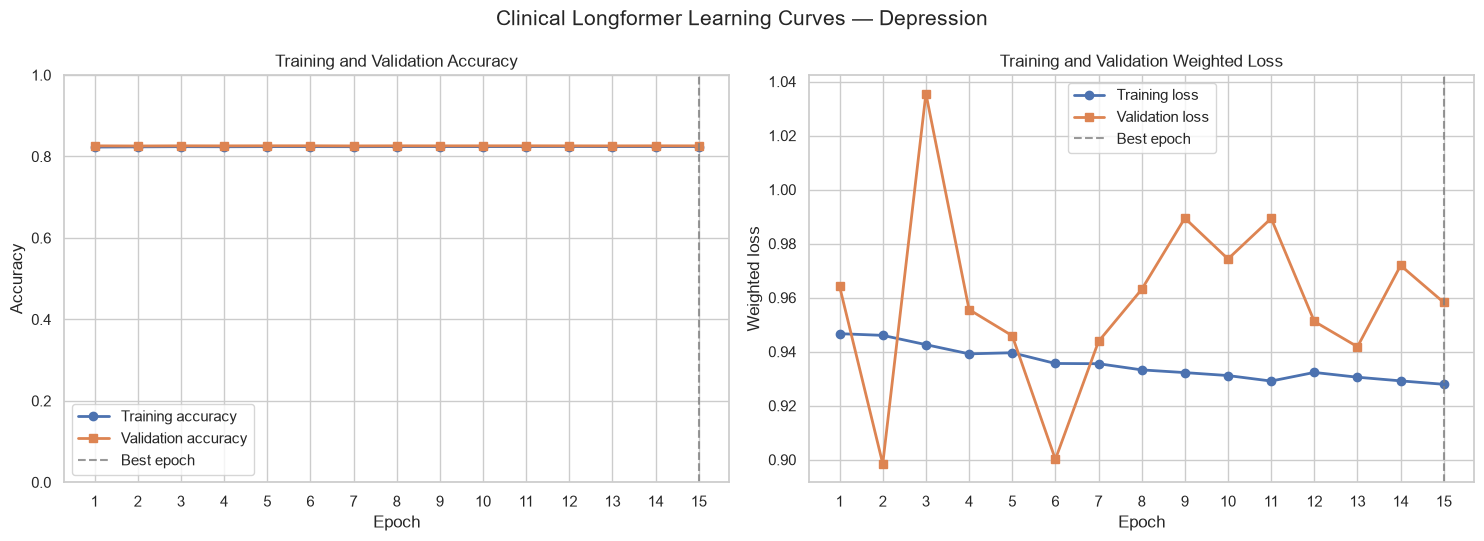

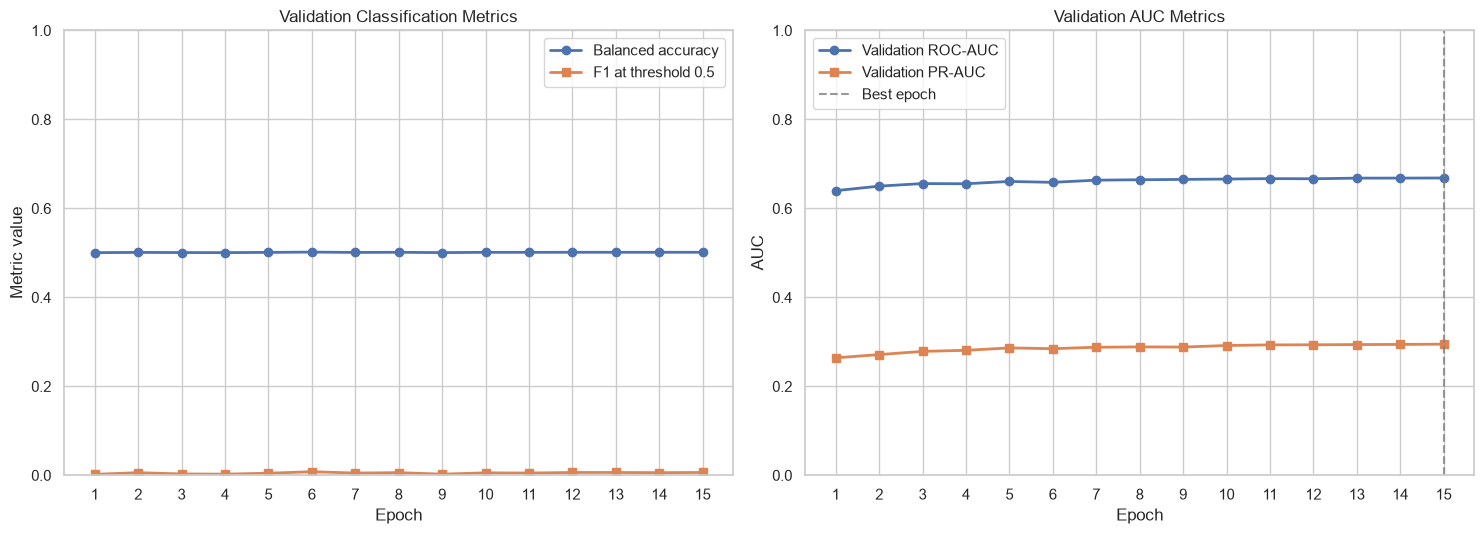

In [67]:
# ============================================================
# CELL 25 - PLOT TRAINING AND VALIDATION HISTORY
# ============================================================

epochs = training_history["epoch"].astype(int)

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5.5))
axes[0].plot(
    epochs,
    training_history["training_accuracy"],
    marker="o",
    linewidth=2,
    label="Training accuracy",
)
axes[0].plot(
    epochs,
    training_history["validation_accuracy"],
    marker="s",
    linewidth=2,
    label="Validation accuracy",
)
axes[0].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
if early_stop_signal_epoch is not None:
    axes[0].axvline(
        early_stop_signal_epoch, color="red", linestyle=":", alpha=0.8, label="Patience reached"
    )
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    training_history["training_loss"],
    marker="o",
    linewidth=2,
    label="Training loss",
)
axes[1].plot(
    epochs,
    training_history["validation_loss"],
    marker="s",
    linewidth=2,
    label="Validation loss",
)
axes[1].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
if early_stop_signal_epoch is not None:
    axes[1].axvline(
        early_stop_signal_epoch, color="red", linestyle=":", alpha=0.8, label="Patience reached"
    )
axes[1].set_title("Training and Validation Weighted Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Weighted loss")
axes[1].set_xticks(epochs)
axes[1].legend()

figure.suptitle(f"Clinical Longformer Learning Curves — {TASK_NAME.title()}", fontsize=15)
figure.tight_layout()
accuracy_loss_plot_path = FIGURE_DIR / "training_validation_accuracy_loss.png"
figure.savefig(accuracy_loss_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5.5))
axes[0].plot(
    epochs,
    training_history["validation_balanced_accuracy"],
    marker="o",
    linewidth=2,
    label="Balanced accuracy",
)
axes[0].plot(
    epochs,
    training_history["validation_f1_at_0_5"],
    marker="s",
    linewidth=2,
    label="F1 at threshold 0.5",
)
axes[0].set_title("Validation Classification Metrics")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Metric value")
axes[0].set_ylim(0, 1)
axes[0].set_xticks(epochs)
axes[0].legend()

axes[1].plot(
    epochs,
    training_history["validation_roc_auc"],
    marker="o",
    linewidth=2,
    label="Validation ROC-AUC",
)
axes[1].plot(
    epochs,
    training_history["validation_pr_auc"],
    marker="s",
    linewidth=2,
    label="Validation PR-AUC",
)
axes[1].axvline(best_epoch, color="grey", linestyle="--", alpha=0.8, label="Best epoch")
axes[1].set_title("Validation AUC Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].set_ylim(0, 1)
axes[1].set_xticks(epochs)
axes[1].legend()

figure.tight_layout()
validation_metric_plot_path = FIGURE_DIR / "validation_metrics_by_epoch.png"
figure.savefig(validation_metric_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
plt.show()


## 9. Select the classification threshold on validation data

The best saved checkpoint is reloaded. Validation probabilities are then used to choose the threshold that maximises validation F1. This is a model-selection decision, so it must be completed without looking at test performance.


In [68]:
# ============================================================
# CELL 26 - RELOAD THE BEST VALIDATION CHECKPOINT
# ============================================================

best_model = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR)
if hasattr(best_model.config, "use_cache"):
    best_model.config.use_cache = False
best_model.to(device=DEVICE, dtype=torch.float32)
best_model.eval()
print("Reloaded best checkpoint from:")
print(BEST_MODEL_DIR)


Loading weights: 100%|██████████| 273/273 [00:00<00:00, 557.24it/s]


Reloaded best checkpoint from:
C:\Users\Administrator\Documents\GitHub\P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection\model_outputs\clinical_longformer_baseline\depression_selected_2048_full\best_model


In [69]:
# ============================================================
# CELL 27 - GENERATE VALIDATION PROBABILITIES
# ============================================================

final_validation_loss, final_validation_labels, final_validation_probabilities = evaluate_model(
    model_object=best_model, data_loader=validation_loader, class_weights=CLASS_WEIGHTS
)
SELECTED_THRESHOLD, selected_validation_f1, validation_threshold_table = select_f1_threshold(
    labels=final_validation_labels, positive_probabilities=(final_validation_probabilities)
)
validation_metrics = calculate_classification_metrics(
    labels=final_validation_labels,
    positive_probabilities=(final_validation_probabilities),
    threshold=SELECTED_THRESHOLD,
)
validation_metrics["weighted_loss"] = float(final_validation_loss)
validation_predictions = split_frames["validation"][
    ["subject_id", "hadm_id", "split", "label", "longformer_token_count", "requires_truncation"]
].copy()
validation_predictions["positive_probability"] = final_validation_probabilities
validation_predictions["predicted_label"] = (
    final_validation_probabilities >= SELECTED_THRESHOLD
).astype(int)
validation_predictions.to_csv(PREDICTION_DIR / "validation_predictions.csv", index=False)
print("Selected validation threshold:", round(SELECTED_THRESHOLD, 6))
print("Validation F1 at selected threshold:", round(selected_validation_f1, 6))
display(pd.DataFrame({"metric": validation_metrics.keys(), "value": validation_metrics.values()}))


Selected validation threshold: 0.172113
Validation F1 at selected threshold: 0.362879


,metric,value
0,threshold,0.172113
1,accuracy,0.674095
2,balanced_accuracy,0.618502
3,precision,0.275022
4,recall,0.533221
5,specificity,0.703783
6,f1,0.362879
7,roc_auc,0.668345
8,pr_auc,0.294787
9,true_negative,15833.000000


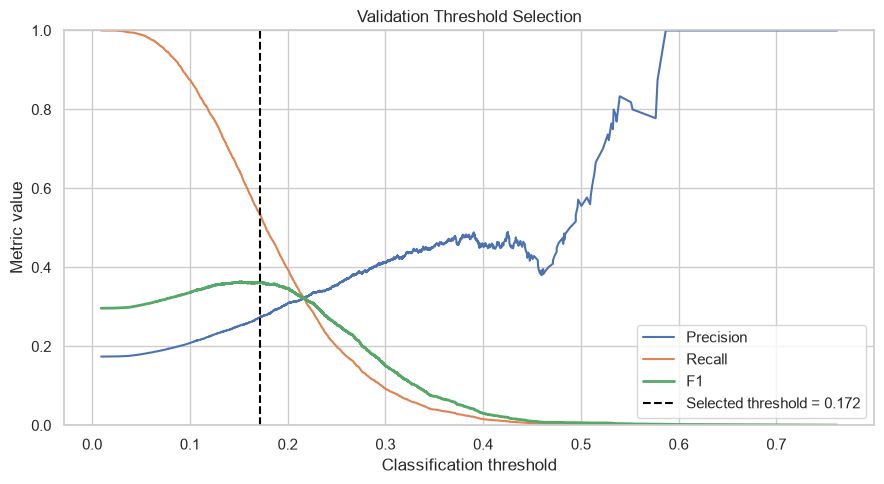

In [70]:
# ============================================================
# CELL 28 - PLOT VALIDATION THRESHOLD SELECTION
# ============================================================

plt.figure(figsize=(9, 5))
plt.plot(
    validation_threshold_table["threshold"],
    validation_threshold_table["precision"],
    label="Precision",
)
plt.plot(
    validation_threshold_table["threshold"], validation_threshold_table["recall"], label="Recall"
)
plt.plot(
    validation_threshold_table["threshold"],
    validation_threshold_table["f1"],
    label="F1",
    linewidth=2,
)
plt.axvline(
    SELECTED_THRESHOLD,
    color="black",
    linestyle="--",
    label=(f"Selected threshold = " f"{SELECTED_THRESHOLD:.3f}"),
)
plt.title("Validation Threshold Selection")
plt.xlabel("Classification threshold")
plt.ylabel("Metric value")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
threshold_plot_path = FIGURE_DIR / "validation_threshold_selection.png"
plt.savefig(threshold_plot_path, dpi=200, bbox_inches="tight")
plt.show()


## 10. Final test-set evaluation

At this point the following decisions are fixed:

- masked dataset and `text_selected` input;
- Clinical Longformer checkpoint;
- 2,048-token maximum context;
- local attention plus global attention on the first token;
- class weights and validation-selected threshold.

The test split is now used for the first and only final evaluation. Do not revise the model, preprocessing or threshold based on the test results.


In [71]:
# ============================================================
# CELL 29 - EVALUATE THE FROZEN MODEL ON THE TEST SET
# ============================================================

test_metrics = None
test_predictions = None
test_classification_report_table = None
if EVALUATE_TEST_SET:
    # --------------------------------------------------------
    # GENERATE TEST PROBABILITIES
    # --------------------------------------------------------

    test_loss, test_labels, test_probabilities = evaluate_model(
        model_object=best_model,
        data_loader=test_loader,
        class_weights=CLASS_WEIGHTS,
        progress_description="Evaluating test data",
    )
    test_predictions_at_threshold = (test_probabilities >= SELECTED_THRESHOLD).astype(int)

    # --------------------------------------------------------
    # CALCULATE OVERALL TEST METRICS
    # --------------------------------------------------------

    test_metrics = calculate_classification_metrics(
        labels=test_labels, positive_probabilities=test_probabilities, threshold=SELECTED_THRESHOLD
    )
    test_metrics["weighted_loss"] = float(test_loss)
    print("Final test metrics:")
    display(pd.DataFrame({"metric": test_metrics.keys(), "value": test_metrics.values()}).round(6))

    # --------------------------------------------------------
    # CREATE THE SKLEARN CLASSIFICATION REPORT
    # --------------------------------------------------------

    test_classification_report = classification_report(
        test_labels,
        test_predictions_at_threshold,
        labels=[0, 1],
        target_names=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        output_dict=True,
        zero_division=0,
    )
    test_classification_report_table = pd.DataFrame(test_classification_report).transpose()
    print("\nTest classification report:")
    display(test_classification_report_table.round(4))

    # --------------------------------------------------------
    # SAVE TEST PREDICTIONS AND CLASSIFICATION REPORT
    # --------------------------------------------------------

    test_predictions = split_frames["test"][
        [
            "subject_id",
            "hadm_id",
            "split",
            "label",
            "longformer_token_count",
            "requires_truncation",
        ]
    ].copy()
    test_predictions["positive_probability"] = test_probabilities
    test_predictions["predicted_label"] = test_predictions_at_threshold
    test_predictions.to_csv(PREDICTION_DIR / "test_predictions.csv", index=False)
    test_classification_report_table.to_csv(
        OUTPUT_DIR / "test_classification_report.csv", index=True
    )
else:
    print("Test evaluation was skipped because " "EVALUATE_TEST_SET is False.")


Final test metrics:


,metric,value
0,threshold,0.172113
1,accuracy,0.677022
2,balanced_accuracy,0.614428
3,precision,0.271048
4,recall,0.518985
5,specificity,0.709872
6,f1,0.356111
7,roc_auc,0.665310
8,pr_auc,0.290383
9,true_negative,15740.000000



Test classification report:


,precision,recall,f1-score,support
no_depression,0.8765,0.7099,0.7845,22173.000
depression,0.2710,0.5190,0.3561,4609.000
accuracy,0.6770,0.6770,0.6770,0.677
macro avg,0.5738,0.6144,0.5703,26782.000
weighted avg,0.7723,0.6770,0.7107,26782.000


### Inspect the first 100 test predictions

The table below is the text-classification equivalent of listing image filenames with predicted and actual classes. It uses admission identifiers, class probabilities, the frozen validation-selected threshold, and a correctness flag. The full prediction file is still saved separately.


In [72]:
# ============================================================
# CELL 29A - DISPLAY THE FIRST 100 TEST PREDICTIONS
# ============================================================

if EVALUATE_TEST_SET:
    prediction_display = test_predictions.head(PREDICTION_DISPLAY_COUNT).copy()
    prediction_display["actual_class"] = prediction_display["label"].map(ID_TO_LABEL)
    prediction_display["predicted_class"] = prediction_display["predicted_label"].map(ID_TO_LABEL)
    prediction_display["prediction_confidence"] = np.where(
        prediction_display["predicted_label"].eq(1),
        prediction_display["positive_probability"],
        1 - prediction_display["positive_probability"],
    )
    prediction_display["correct"] = prediction_display["label"].eq(
        prediction_display["predicted_label"]
    )

    prediction_display_columns = [
        "subject_id",
        "hadm_id",
        "actual_class",
        "predicted_class",
        "positive_probability",
        "prediction_confidence",
        "correct",
        "longformer_token_count",
        "requires_truncation",
    ]
    prediction_display_output = prediction_display[prediction_display_columns]
    prediction_display_output.to_csv(
        PREDICTION_DIR / "test_predictions_first_100.csv",
        index=False,
    )

    print(
        f"Displaying {len(prediction_display_output)} of "
        f"{len(test_predictions):,} test predictions:"
    )
    with pd.option_context("display.max_rows", PREDICTION_DISPLAY_COUNT):
        display(
            prediction_display_output.style.format(
                {
                    "positive_probability": "{:.4f}",
                    "prediction_confidence": "{:.4f}",
                }
            )
        )
else:
    print("Prediction display skipped because EVALUATE_TEST_SET is False.")


Displaying 100 of 26,782 test predictions:


,subject_id,hadm_id,actual_class,predicted_class,positive_probability,prediction_confidence,correct,longformer_token_count,requires_truncation
0,10000980,29654838,no_depression,depression,0.1879,0.1879,False,1709,False
1,10000980,26913865,no_depression,no_depression,0.1418,0.8582,True,1301,False
2,10000980,24947999,no_depression,depression,0.1741,0.1741,False,2119,True
3,10000980,25242409,no_depression,no_depression,0.1633,0.8367,True,796,False
4,10000980,25911675,no_depression,depression,0.1976,0.1976,False,1301,False
5,10000980,29659838,no_depression,depression,0.1837,0.1837,False,1967,False
6,10000980,20897796,no_depression,no_depression,0.0603,0.9397,True,870,False
7,10001401,21544441,no_depression,no_depression,0.0943,0.9057,True,548,False
8,10001401,26840593,no_depression,no_depression,0.1399,0.8601,True,895,False
9,10001401,24818636,no_depression,no_depression,0.1545,0.8455,True,1613,False


In [ ]:
# ============================================================
# CELL 30 - DISPLAY REPORT-READY CONFUSION MATRIX AND CURVES
# ============================================================

if EVALUATE_TEST_SET:
    test_confusion_matrix = confusion_matrix(
        test_labels,
        test_predictions_at_threshold,
        labels=[0, 1],
    )
    false_positive_rates, true_positive_rates, _ = roc_curve(
        test_labels,
        test_probabilities,
        drop_intermediate=False,
    )
    test_precision_values, test_recall_values, _ = precision_recall_curve(
        test_labels,
        test_probabilities,
    )

    # A large, separate confusion matrix is easier to use in the report.
    figure, axis = plt.subplots(figsize=(9, 7))
    sns.heatmap(
        test_confusion_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=True,
        square=True,
        annot_kws={"size": 18, "weight": "bold"},
        xticklabels=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        yticklabels=[ID_TO_LABEL[0], ID_TO_LABEL[1]],
        ax=axis,
    )
    axis.set_title(
        f"Clinical Longformer Test Confusion Matrix — {TASK_NAME.title()}",
        fontsize=16,
        pad=16,
    )
    axis.set_xlabel("Predicted class", fontsize=13)
    axis.set_ylabel("Actual class", fontsize=13)
    axis.tick_params(axis="both", labelsize=11)
    figure.tight_layout()
    confusion_matrix_plot_path = FIGURE_DIR / "test_confusion_matrix.png"
    figure.savefig(
        confusion_matrix_plot_path,
        dpi=REPORT_FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()

    # ROC and PR curves are empirical threshold curves. Their stair-step
    # appearance is expected, especially for a 200-record smoke test.
    figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
    axes[0].step(
        false_positive_rates,
        true_positive_rates,
        where="post",
        linewidth=2,
        label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}",
    )
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
    axes[0].set_title("Empirical ROC Curve")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1.02)
    axes[0].legend(loc="lower right")

    positive_prevalence = float(np.mean(test_labels))
    axes[1].step(
        test_recall_values[::-1],
        test_precision_values[::-1],
        where="post",
        linewidth=2,
        label=f"PR-AUC = {test_metrics['pr_auc']:.3f}",
    )
    axes[1].axhline(
        positive_prevalence,
        linestyle="--",
        color="grey",
        label=f"Positive prevalence = {positive_prevalence:.3f}",
    )
    axes[1].set_title("Empirical Precision–Recall Curve")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(loc="best")

    figure.suptitle(
        f"Clinical Longformer Test Evaluation — {TASK_NAME.title()}",
        fontsize=16,
    )
    figure.tight_layout()
    roc_pr_plot_path = FIGURE_DIR / "test_roc_pr_curves.png"
    figure.savefig(roc_pr_plot_path, dpi=REPORT_FIGURE_DPI, bbox_inches="tight")
    plt.show()

    print(
        "The step shape is statistically correct: each change occurs at an "
        "observed probability threshold. A larger full test set normally makes "
        "the curves appear denser; artificial smoothing has not been applied."
    )


## 11. Save a Flask-ready deployment bundle

The portable bundle contains the best Hugging Face model in `safetensors` format, its tokenizer and a JSON inference contract. The included predictor recreates both the ordinary attention mask and the required first-token global-attention mask.

The model was trained on masked `text_selected`. Production input must therefore pass through the same Notebook 03 section-selection, cleaning and masking rules before inference.


In [ ]:
# ============================================================
# CELL 31 - SAVE A FLASK-READY DEPLOYMENT BUNDLE
# ============================================================

best_model.save_pretrained(DEPLOYMENT_MODEL_DIR, safe_serialization=True)
tokenizer.save_pretrained(DEPLOYMENT_MODEL_DIR)
deployment_configuration = {
    "task": TASK_NAME,
    "model_name": MODEL_NAME,
    "training_strategy": TRAINING_STRATEGY,
    "model_subdirectory": "model",
    "positive_label": ID_TO_LABEL[1],
    "negative_label": ID_TO_LABEL[0],
    "positive_label_id": 1,
    "negative_label_id": 0,
    "classification_threshold": float(SELECTED_THRESHOLD),
    "maximum_length": MAX_LENGTH,
    "attention_window": LONGFORMER_ATTENTION_WINDOW,
    "training_text_column": TEXT_COLUMN,
    "global_attention_policy": "first_token",
    "expects_masked_text": True,
    "expects_selected_sections": TEXT_COLUMN == "text_selected",
    "input_contract": (
        "Apply the same Notebook 03 cleaning, clinical-section selection and masking "
        "before calling the model."
    ),
}
with open(
    DEPLOYMENT_BUNDLE_DIR / "inference_config.json", "w", encoding="utf-8"
) as configuration_file:
    json.dump(deployment_configuration, configuration_file, indent=2)

deployment_loader_source = r"""from pathlib import Path
import json
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

class ClinicalLongformerPredictor:
    # Load once when Flask starts and reuse for every request.

    def __init__(self, bundle_directory, device=None):
        self.bundle_directory = Path(bundle_directory)
        with open(
            self.bundle_directory / "inference_config.json", "r", encoding="utf-8"
        ) as configuration_file:
            self.configuration = json.load(configuration_file)
        model_directory = self.bundle_directory / self.configuration["model_subdirectory"]
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.tokenizer = AutoTokenizer.from_pretrained(model_directory)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_directory)
        self.model.to(self.device)
        self.model.eval()

    @torch.inference_mode()
    def predict(self, preprocessed_texts):
        if isinstance(preprocessed_texts, str):
            preprocessed_texts = [preprocessed_texts]
        encoded = self.tokenizer(
            list(preprocessed_texts),
            truncation=True,
            max_length=self.configuration["maximum_length"],
            padding=True,
            pad_to_multiple_of=self.configuration["attention_window"],
            return_tensors="pt",
        )
        global_attention_mask = torch.zeros_like(encoded["attention_mask"])
        global_attention_mask[:, 0] = 1
        encoded["global_attention_mask"] = global_attention_mask
        encoded = {name: value.to(self.device) for name, value in encoded.items()}
        logits = self.model(**encoded).logits
        positive_probabilities = torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy()
        threshold = self.configuration["classification_threshold"]
        return [
            {
                "positive_probability": float(probability),
                "predicted_label_id": int(probability >= threshold),
                "predicted_label": (
                    self.configuration["positive_label"]
                    if probability >= threshold
                    else self.configuration["negative_label"]
                ),
                "threshold": float(threshold),
            }
            for probability in positive_probabilities
        ]
"""
(DEPLOYMENT_BUNDLE_DIR / "clinical_longformer_inference.py").write_text(
    deployment_loader_source, encoding="utf-8"
)
deployment_readme = f"""Clinical Longformer frozen-encoder baseline deployment bundle
======================================

Task: {TASK_NAME}
Model: {MODEL_NAME}
Threshold: {SELECTED_THRESHOLD:.8f}
Maximum input length: {MAX_LENGTH} tokens
Global attention: first token

The model expects text processed exactly like Notebook 03:
- selected clinical sections
- cleaned text
- masked explicit depression/anxiety terms

Flask usage:
    from clinical_longformer_inference import ClinicalLongformerPredictor
    predictor = ClinicalLongformerPredictor('/path/to/deployment_bundle')
    result = predictor.predict(preprocessed_text)

Load the predictor once when Flask starts. Do not reload it per request.
"""
(DEPLOYMENT_BUNDLE_DIR / "README.txt").write_text(
    deployment_readme, encoding="utf-8"
)
print("Flask-ready deployment bundle saved to:")
print(DEPLOYMENT_BUNDLE_DIR)
print("\nBundle contents:")
for bundle_path in sorted(DEPLOYMENT_BUNDLE_DIR.rglob("*")):
    if bundle_path.is_file():
        print("-", bundle_path.relative_to(DEPLOYMENT_BUNDLE_DIR))


## 12. Save the run metadata and outputs

The final cells save enough information to reproduce and audit the experiment:

- best model and tokenizer;
- training history;
- exact token-length and truncation summary;
- validation predictions and selected threshold;
- test predictions and metrics;
- run configuration and package versions.


In [ ]:
# ============================================================
# CELL 32 - SAVE METRICS AND RUN MANIFEST
# ============================================================

def convert_to_json_value(value):
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Cannot serialise value of type {type(value).__name__}.")

metrics_output = {"validation": validation_metrics, "test": test_metrics}
run_manifest = {
    "run_name": RUN_NAME,
    "task": TASK_NAME,
    "dataset_path": str(DATASET_PATH),
    "dataset_is_masked": True,
    "text_column": TEXT_COLUMN,
    "model_name": MODEL_NAME,
    "training_strategy": TRAINING_STRATEGY,
    "maximum_length": MAX_LENGTH,
    "attention_window": LONGFORMER_ATTENTION_WINDOW,
    "global_attention_policy": "first_token",
    "input_strategy": "single selected note with truncation; no chunking",
    "seed": SEED,
    "smoke_test": SMOKE_TEST,
    "split_rows": {name: len(split_frames[name]) for name in SPLIT_ORDER},
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_proportion": WARMUP_PROPORTION,
    "maximum_gradient_norm": MAX_GRADIENT_NORM,
    "epochs_requested": NUMBER_OF_EPOCHS,
    "last_completed_epoch": last_completed_epoch,
    "stop_training_when_patience_reached": STOP_TRAINING_WHEN_PATIENCE_REACHED,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_minimum_improvement": EARLY_STOPPING_MINIMUM_IMPROVEMENT,
    "early_stop_signal_epoch": early_stop_signal_epoch,
    "training_batch_size": TRAIN_BATCH_SIZE,
    "evaluation_batch_size": EVALUATION_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "effective_batch_size": TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
    "mixed_precision": AMP_ENABLED,
    "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
    "frozen_encoder_verified": FROZEN_BASELINE_VERIFIED,
    "total_parameters": total_parameter_count,
    "trainable_parameters": trainable_parameter_count,
    "frozen_parameters": frozen_parameter_count,
    "best_model_directory": str(BEST_MODEL_DIR),
    "early_stop_signal_model_directory": str(EARLY_STOP_SIGNAL_MODEL_DIR),
    "final_epoch_model_directory": str(FINAL_EPOCH_MODEL_DIR),
    "best_epoch": best_epoch,
    "best_validation_pr_auc": best_validation_pr_auc,
    "selected_validation_threshold": SELECTED_THRESHOLD,
    "deployment_bundle": str(DEPLOYMENT_BUNDLE_DIR),
    "class_weights": class_weight_values.tolist(),
    "token_length_summary": token_length_summary.to_dict(orient="records"),
    "context_length_audit": context_length_audit.to_dict(orient="records"),
    "package_versions": {
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": hf_datasets.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "device": str(DEVICE),
    "total_training_seconds": total_training_seconds,
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as metrics_file:
    json.dump(metrics_output, metrics_file, indent=2, default=convert_to_json_value)
with open(OUTPUT_DIR / "run_manifest.json", "w", encoding="utf-8") as manifest_file:
    json.dump(run_manifest, manifest_file, indent=2, default=convert_to_json_value)

token_length_summary.to_csv(OUTPUT_DIR / "token_length_summary.csv", index=False)
context_length_audit.to_csv(OUTPUT_DIR / "context_length_audit.csv", index=False)
working_split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
print("Run outputs saved to:")
print(OUTPUT_DIR)


In [ ]:
# ============================================================
# CELL 33 - DISPLAY THE FINAL OUTPUT SUMMARY
# ============================================================

output_files = sorted(path for path in OUTPUT_DIR.rglob("*") if path.is_file())
output_file_table = pd.DataFrame(
    {
        "file": [str(path.relative_to(OUTPUT_DIR)) for path in output_files],
        "size_mb": [round(path.stat().st_size / 1_048_576, 3) for path in output_files],
    }
)
display(output_file_table)
selected_context_truncation = token_length_summary.set_index("split").loc[
    "test", "truncation_percentage"
]
final_summary = pd.DataFrame(
    {
        "item": [
            "Task", "Run mode", "Training strategy", "Masked dataset",
            "Input text", "Maximum tokens", "Test truncation percentage",
            "Best epoch", "Early-stop signal epoch", "Last completed epoch",
            "Frozen encoder verified", "Total parameters",
            "Trainable classification-head parameters", "Trainable percentage",
            "Training batch size", "Effective batch size", "Learning rate",
            "Best validation PR-AUC", "Selected validation threshold", "Test F1",
            "Test PR-AUC", "Test ROC-AUC", "Deployment bundle",
        ],
        "value": [
            TASK_NAME, RUN_MODE, TRAINING_STRATEGY, DATASET_PATH.name,
            TEXT_COLUMN, MAX_LENGTH, selected_context_truncation, best_epoch,
            early_stop_signal_epoch, last_completed_epoch,
            FROZEN_BASELINE_VERIFIED, total_parameter_count,
            trainable_parameter_count, trainable_percentage, TRAIN_BATCH_SIZE,
            TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS, LEARNING_RATE,
            best_validation_pr_auc, SELECTED_THRESHOLD,
            test_metrics["f1"] if test_metrics is not None else "Not evaluated",
            test_metrics["pr_auc"] if test_metrics is not None else "Not evaluated",
            test_metrics["roc_auc"] if test_metrics is not None else "Not evaluated",
            str(DEPLOYMENT_BUNDLE_DIR),
        ],
    }
)
display(final_summary)

## 13. Recommended execution order

1. Restart the CUDA kernel so no previous model occupies GPU memory.
2. Run a depression smoke test with `TASK_NAME = "depression"` and `SMOKE_TEST = True`.
3. Run an anxiety smoke test with `TASK_NAME = "anxiety"` and `SMOKE_TEST = True`.
4. Confirm the context-length audit, global-attention check, forward pass, frozen-encoder audit and complete output pipeline.
5. Freeze all experimental settings.
6. Run depression in full mode with `SMOKE_TEST = False`.
7. Restart the kernel, copy the notebook, change only `TASK_NAME = "anxiety"`, and run full mode again.
8. Compare each frozen-encoder result with the corresponding fully fine-tuned Clinical Longformer result.

## Memory guidance

The default settings target a 16 GB Tesla T4. The frozen encoder uses less training memory than full fine-tuning, but the 2,048-token forward pass is still large. If a genuine CUDA out-of-memory error occurs, restart the kernel and reduce `EVALUATION_BATCH_SIZE` from 2 to 1. Keep `TRAIN_BATCH_SIZE = 1` for direct comparability with the fine-tuned experiment.

## Interpretation boundary

This baseline uses the fixed pretrained Clinical Longformer encoder as a long-context feature extractor and learns only the binary classification head. It does not adapt pretrained encoder representations to depression or anxiety. The full parameter audit must report that every pretrained tensor stayed unchanged before the run can be described as a valid frozen-encoder baseline.